# 06 — Independent Robustness, Validation & Scientific Acceptance
**Dubai Real Estate Analytics V2 · Final independent research audit (RQ01–RQ15)**

**Scientific contract.** Independently reconstruct critical estimates from the immutable snapshot; reconcile upstream exports and executed notebooks; challenge selection, statistical identification, uncertainty and dashboard safety. This notebook is **not** a repeat-sales index, a causal estimate, an investment recommendation or an automatic upstream PASS collector.

**Five research outcomes:** `SUPPORTED`, `QUALIFIED`, `INCONCLUSIVE`, `NOT ESTIMABLE`, `BLOCKED`. An unavailable input is **BLOCKED / NOT VERIFIED**, never a fabricated numerical result. 2026 is explicitly provisional and excluded from annual historical estimates.

**IMPORTANT:** Full verification requires the original raw Parquet, all six *executed* notebooks, upstream CSV/Parquet exports and the seven source modules. The notebook remains executable under incomplete evidence, but issues claim-level publication blocks instead of inventing findings.
**Release gates and scientific claim decisions are independent.** A missing export can block publication without rewriting a verified observational finding as mathematically invalid.


> **Execution provenance (corrected edition):** Unmodified analytical cells may display saved real-data outputs from the supplied `06_Robustness_Validation(3).ipynb`. Those outputs were produced *before* these code changes and are historical evidence, **not execution of this corrected version**. All changed cells have their outputs cleared. The corrected notebook must be restarted and executed against the frozen real dataset in the validated `dubai-v2` environment before its new export and release assessments are authoritative.


## 01 — Audit governance and provenance
**Independence levels:** A = independent transaction-level recomputation; B = distinct estimator; C = algebraic/synthetic oracle; D = saved artifact cross-check; E = reusing original helper only. Never describe E as A. Decimal differences are tested with declared tolerances; dissimilar estimands are **not directly comparable**.

In [1]:
from __future__ import annotations
import os, sys, json, gc, re, math, hashlib, platform, subprocess, traceback, warnings
from pathlib import Path
from io import StringIO
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT_CANDIDATES=[Path.cwd(), *Path.cwd().parents]
ROOT=next((p.resolve() for p in ROOT_CANDIDATES if (p/'src'/'loader.py').is_file()),Path.cwd().resolve())
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
from src.config import (SNAPSHOT_SHA256, COARSE_AREA_BANDS_SQM,FINE_AREA_BANDS_SQM,
    MATCHING_DESIGNS,HISTORICAL_START_YEAR,HISTORICAL_END_YEAR,
    PRIMARY_BASE_YEAR,PRIMARY_END_YEAR,NOMINAL_BUDGET_THRESHOLDS_AED)
from src.loader import DEFAULT_SOURCE
from src.validation import REQUIRED_COLUMNS
from src.cleaning import COHORT_COLUMNS, clean_transactions
from src.features import engineer_features
TABLE_DIR=ROOT/'reports'/'tables'; AGG_DIR=ROOT/'data'/'aggregates'; FIG_DIR=ROOT/'reports'/'figures'
NOTEBOOK_DIR=ROOT/'notebooks'; SOURCE=ROOT/DEFAULT_SOURCE
RUN_UTC=datetime.now(timezone.utc).strftime('%Y-%m-%dT%H:%M:%SZ')
RUN_ID='06-'+datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
TABLES={}; FIGURES=[]; CHECKS=[]; ISSUES=[]; COMPARES=[]; CLAIM_RQ={}
EXPECTED_NOTEBOOKS={f'{j:02d}':name for j,name in enumerate(['Data_Quality_Audit','Market_Overview','Price_Composition','Market_Activity','Community_Intelligence','Market_Structure'])}
RQ_IDS=[f'RQ{i:02d}' for i in range(1,16)]
STATUSES={'SUPPORTED','QUALIFIED','INCONCLUSIVE','NOT ESTIMABLE','BLOCKED'}
print('Project root:',ROOT,'| audit run:',RUN_ID)
print('Raw file:',SOURCE,'| exists:',SOURCE.is_file())

Project root: E:\DataAnalytics\Projects\Dubai_Real_Estate_Analytics_V2 | audit run: 06-20261124T040907Z
Raw file: E:\DataAnalytics\Projects\Dubai_Real_Estate_Analytics_V2\data\raw\dld_sales_transactions.parquet | exists: True


In [2]:
def digest(path,chunk=4*1024*1024):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        while buf:=f.read(chunk):h.update(buf)
    return h.hexdigest()

def issue(section,code,severity,detail,claims='ALL',source='06 independent audit'):
    ISSUES.append(dict(section=section,code=code,severity=severity,detail=str(detail),
                       affected_rqs=claims,source=source,detected_at=RUN_ID))

def check(section,name,passed,details='',independence='C',claims='ALL',critical=False):
    passed=bool(passed)
    CHECKS.append(dict(section=section,check=name,passed=passed,details=str(details),
                       independence_level=independence,affected_rqs=claims,critical=bool(critical)))
    if not passed and critical:issue(section,'CHECK_FAILED','BLOCKED',f'{name}: {details}',claims)
    return passed

def expose(name,frame,limit=8):
    if not isinstance(frame,pd.DataFrame):raise TypeError(f'{name} not DataFrame')
    TABLES[name]=frame.copy()
    print(f'{name}: {len(frame):,} rows, {len(frame.columns)} columns')
    if not frame.empty:display(frame.head(limit))
    return frame

def load_export(prefix,stem,required=False,claims='ALL'):
    path=TABLE_DIR/f'{prefix}_{stem}.csv'
    if not path.is_file():
        if required:issue('ARTIFACTS','UPSTREAM_MISSING','BLOCKED',str(path),claims)
        return pd.DataFrame()
    try:return pd.read_csv(path,low_memory=False)
    except Exception as exc:
        issue('ARTIFACTS','UPSTREAM_UNREADABLE','BLOCKED',f'{path}: {exc}',claims)
        return pd.DataFrame()

def validate_against(df,reference,columns,keys,section,rq,atol=1e-7,rtol=1e-9):
    if df.empty or reference.empty:return check(section,f'{rq} comparable exports present',False,'Missing evidence',claims=rq,critical=True)
    missing=(set(columns+keys)-set(df.columns)) | (set(columns+keys)-set(reference.columns))
    if missing:return check(section,f'{rq} comparable export schema',False,f'Missing {missing}',claims=rq,critical=True)
    a=df[keys+columns].sort_values(keys).reset_index(drop=True)
    b=reference[keys+columns].sort_values(keys).reset_index(drop=True)
    good=a[keys].equals(b[keys]) and len(a)==len(b)
    for col in columns:
        if pd.api.types.is_numeric_dtype(a[col]):
            good &= np.allclose(a[col].to_numpy(float),pd.to_numeric(b[col],errors='coerce').to_numpy(float),rtol=rtol,atol=atol,equal_nan=True)
        else:good &= a[col].fillna('<NA>').astype(str).equals(b[col].fillna('<NA>').astype(str))
    return check(section,f'{rq} equivalent-estimand comparison',good,claims=rq,independence='A',critical=True)

# Missing data cannot be converted to a passing validation. Computation failures are recorded.
def raw_result(name,fn,claims='ALL'):
    if not DATA_OK:
        return expose(name,pd.DataFrame())
    try:
        result=fn()
        return expose(name,result if isinstance(result,pd.DataFrame) else pd.DataFrame(result))
    except Exception as exc:
        issue(name,'INDEPENDENT_CALC_FAILED','BLOCKED',f'{type(exc).__name__}: {exc}',claims)
        print(f'{name} — BLOCKED: {type(exc).__name__}: {exc}')
        return expose(name,pd.DataFrame())

def registration_label(series):
    return series.where(series.isin(['Ready','Off-Plan']),other='Unknown')

def _ratio(num,den):return 100*num/den if den>0 else float('nan')

def _close(a,b,atol=1e-7,rtol=1e-9):
    return bool(np.isclose(float(a),float(b),atol=atol,rtol=rtol,equal_nan=False))

print('Audit helpers registered; computations fail closed.')
# Independent audit policy: scientific claims and release packaging are separate gates.
# These functions do not use upstream scientific estimators.
def normalize_rqs(value):
    if value is None:return set()
    if isinstance(value,(tuple,list,set)):return set().union(*(normalize_rqs(x) for x in value))
    s=str(value).strip()
    if s.upper()=='ALL':return set(RQ_IDS)
    return {f'RQ{int(x):02d}' for x in re.findall(r'(?<![A-Za-z0-9])RQ\s*0?([1-9]|1[0-5])(?![0-9])',s,re.I)}

def map_claim_rq(record):
    """Structured RQ fields take precedence; conflicts are never guessed away."""
    direct=[]; invalid_structured=[]
    for field in ('research_question','rq_id','rq'):
        value=record.get(field)
        if value is None or (not isinstance(value,(list,dict,set,tuple)) and bool(pd.isna(value))):continue
        hit=normalize_rqs(str(value))
        if len(hit)>1:return None,'AMBIGUOUS_STRUCTURED_RQ'
        if hit:direct.extend(hit)
        elif str(value).strip():invalid_structured.append(field)
    if invalid_structured:
        # Source-verified Notebook 03 activity captions are legitimate RQ04 claims.
        known_activity_labels={('03','ACT01','Growth dynamics'),
                               ('03','ACT02','Growth persistence')}
        source_key=(str(record.get('source_notebook','')).strip(),
                    str(record.get('claim_id','')).strip(),
                    str(record.get('research_question','')).strip())
        if source_key in known_activity_labels and invalid_structured==['research_question']:
            if direct and set(direct)!={'RQ04'}:
                return None,'CONFLICTING_STRUCTURED_RQ'
            return 'RQ04',''
        # Notebook 04 contains a legitimate cross-cutting 'COM01 — Evidence reliability'
        # finding. Never invent an RQ15 mapping or discard it as a malformed RQ.
        if (str(record.get('claim_id','')).strip()=='COM01' and
            str(record.get('research_question','')).strip().lower()=='evidence reliability'):
            return None,'CROSS_CUTTING_SOURCE_FINDING'
        return None,'INVALID_STRUCTURED_RQ:'+','.join(invalid_structured)
    if direct:
        if len(set(direct))!=1:return None,'CONFLICTING_STRUCTURED_RQ'
        return direct[0],''
    # Notebook 03's published activity findings use prose rather than RQ IDs.
    # This is a narrowly scoped, source-verified crosswalk, NOT a general ACT* rule.
    known_activity_claims={
        ('03','ACT01','Growth dynamics'):'RQ04',
        ('03','ACT02','Growth persistence'):'RQ04',
    }
    src=str(record.get('source_notebook','')).strip()
    claim=str(record.get('claim_id','')).strip()
    label=str(record.get('research_question','')).strip()
    if (src,claim,label) in known_activity_claims:
        return known_activity_claims[(src,claim,label)],''
    match=normalize_rqs(str(record.get('claim_id','')))
    if len(match)==1:return next(iter(match)),''
    return None,'RQ_NOT_EXPLICITLY_IDENTIFIED'

def verify_frame_values(left,right,atol=1e-14,rtol=1e-12):
    """Typed, full-value comparison after Parquet readback; exact null positions.
    Ints and booleans compare exactly; floats use explicit numerical tolerance.
    """
    a=left.reset_index(drop=True);b=right.reset_index(drop=True)
    if a.shape!=b.shape or list(a.columns)!=list(b.columns):
        return False,'SCHEMA_OR_SHAPE'
    for col in a.columns:
        x,y=a[col],b[col]
        if not x.isna().equals(y.isna()):return False,f'{col}:NULL_MASK'
        good=x.notna()
        if not bool(good.any()):continue
        x,y=x[good].reset_index(drop=True),y[good].reset_index(drop=True)
        xb=(pd.api.types.is_bool_dtype(x.dtype) or
            x.map(lambda v:isinstance(v,(bool,np.bool_))).all())
        yb=(pd.api.types.is_bool_dtype(y.dtype) or
            y.map(lambda v:isinstance(v,(bool,np.bool_))).all())
        xn=pd.api.types.is_numeric_dtype(x.dtype) or x.map(
            lambda v:isinstance(v,(int,float,np.integer,np.floating)) and
                     not isinstance(v,(bool,np.bool_))).all()
        yn=pd.api.types.is_numeric_dtype(y.dtype) or y.map(
            lambda v:isinstance(v,(int,float,np.integer,np.floating)) and
                     not isinstance(v,(bool,np.bool_))).all()
        if xb or yb:
            if not(xb and yb):return False,f'{col}:BOOLEAN_DTYPE'
            if not x.astype(bool).equals(y.astype(bool)):
                return False,f'{col}:BOOLEAN_VALUES'
        elif pd.api.types.is_integer_dtype(x.dtype) and pd.api.types.is_integer_dtype(y.dtype):
            if not all(int(i)==int(j) for i,j in zip(x,y)):
                return False,f'{col}:INTEGER_VALUES'
        elif xn and yn:
            xv=pd.to_numeric(x).to_numpy(dtype=float);yv=pd.to_numeric(y).to_numpy(dtype=float)
            if not np.allclose(xv,yv,rtol=rtol,atol=atol,equal_nan=False):
                return False,f'{col}:NUMERIC_VALUES'
        elif pd.api.types.is_datetime64_any_dtype(x.dtype) or pd.api.types.is_datetime64_any_dtype(y.dtype):
            if not pd.to_datetime(x,utc=True).equals(pd.to_datetime(y,utc=True)):
                return False,f'{col}:DATETIME_VALUES'
        elif not x.astype(str).equals(y.astype(str)):
            return False,f'{col}:CATEGORY_VALUES'
    return True,'VALUES_AND_MISSINGNESS_VERIFIED'

def relevant_blockers(rq,items,source_data_ok=True):
    """Only scientific failures that actually depend on rq block its scientific decision.
    Export, tests, final reports and project-wide packaging affect release readiness.
    """
    release_sections={'EXPORT','FINAL_EXPORT','FIGURES','TESTS','ARTIFACTS','EXECUTION'}
    blockers=[]
    for item in items:
        if item.get('severity')!='BLOCKED':continue
        section=item.get('section','')
        if section in release_sections:continue
        affected=normalize_rqs(item.get('affected_rqs'))
        if rq in affected and (section in {'SOURCE','POPULATIONS','COHORTS','CLAIMS'} or section.startswith('RQ') or item.get('code')=='CHECK_FAILED'):
            blockers.append(item)
    return blockers

def release_gate(issues,export_manifest,figure_manifest,pytest_ok,source_ok,notebooks_ok):
    blockers=[x for x in issues if x.get('severity')=='BLOCKED']
    export_ok=not export_manifest.empty and export_manifest.status.isin(['VERIFIED','WITHHELD_EMPTY']).all()
    figure_ok=figure_manifest.empty or figure_manifest.exists.all()
    return bool(source_ok and notebooks_ok and pytest_ok and export_ok and figure_ok and not blockers)


Audit helpers registered; computations fail closed.


In [3]:
notebook_rows=[]; UPSTREAM_NBS={}
for prefix,stem in EXPECTED_NOTEBOOKS.items():
    path=NOTEBOOK_DIR/f'{prefix}_{stem}.ipynb'
    if not path.exists():
        notebook_rows.append(dict(notebook=prefix,path=str(path),exists=False,sha256=None,cells=0,
                                  code_cells=0,executed_code=0,error_outputs=0,status='MISSING'))
        issue('EXECUTION','NOTEBOOK_MISSING','BLOCKED',str(path),f'RQ from Notebook {prefix}')
        continue
    try:
        obj=json.loads(path.read_text(encoding='utf-8'));UPSTREAM_NBS[prefix]=obj
        codes=[c for c in obj.get('cells',[]) if c.get('cell_type')=='code']
        errors=sum(x.get('output_type')=='error' for c in codes for x in c.get('outputs',[]))
        executed=sum(c.get('execution_count') is not None for c in codes)
        good=errors==0 and executed==len(codes) and bool(codes)
        notebook_rows.append(dict(notebook=prefix,path=str(path),exists=True,sha256=digest(path),cells=len(obj['cells']),
                                  code_cells=len(codes),executed_code=executed,error_outputs=errors,status='COMPLETE' if good else 'INCOMPLETE'))
        if not good:issue('EXECUTION','UPSTREAM_INCOMPLETE','BLOCKED',f'{path}: {executed}/{len(codes)} code cells; {errors} errors',prefix)
    except Exception as exc:
        notebook_rows.append(dict(notebook=prefix,path=str(path),exists=True,status='UNREADABLE',sha256=None,cells=0,code_cells=0,executed_code=0,error_outputs=0))
        issue('EXECUTION','NOTEBOOK_PARSE','BLOCKED',f'{path}: {exc}',prefix)
execution_inventory=expose('06_notebook_execution_inventory',pd.DataFrame(notebook_rows))
environment_manifest=expose('06_environment_manifest',pd.DataFrame([dict(run_id=RUN_ID,python=sys.version.split()[0],
    pandas=pd.__version__,numpy=np.__version__,platform=platform.platform(),
    source_module=name,sha256=digest(ROOT/'src'/name) if (ROOT/'src'/name).is_file() else None)
    for name in ['loader.py','validation.py','cleaning.py','features.py','statistics.py','visualization.py','config.py']]))
artifact_rows=[]
for directory,extension in [(TABLE_DIR,'.csv'),(AGG_DIR,'.parquet'),(FIG_DIR,'.png')]:
    for path in sorted(directory.glob('*')) if directory.is_dir() else []:
        if path.is_file() and path.suffix.lower()==extension and path.name.startswith(tuple(f'{i:02d}_' for i in range(6))):
            artifact_rows.append(dict(path=str(path),filename=path.name,bytes=path.stat().st_size,sha256=digest(path),kind=extension))
upstream_artifact_inventory=expose('06_upstream_artifact_inventory',pd.DataFrame(artifact_rows) if artifact_rows else pd.DataFrame(columns=['path','filename','bytes','sha256','kind']))

06_notebook_execution_inventory: 6 rows, 9 columns


,notebook,path,exists,sha256,cells,code_cells,executed_code,error_outputs,status
0,00,E:\DataAnalytics\Projects\Dubai_Real_Estate_An...,True,594e1cde21bf0f85020f0018a36249e9d758bf43f8f9bf...,37,27,27,0,COMPLETE
1,01,E:\DataAnalytics\Projects\Dubai_Real_Estate_An...,True,7042e226ff3a44e5d924440e1227137c41b0831756bfe3...,36,23,23,0,COMPLETE
2,02,E:\DataAnalytics\Projects\Dubai_Real_Estate_An...,True,a1919fd4591050bba60a21a95daf4eac54890ddd07cd10...,46,33,33,0,COMPLETE
3,03,E:\DataAnalytics\Projects\Dubai_Real_Estate_An...,True,4b07708aae5d1253736ba49c211a136d580b3984a75436...,48,34,34,0,COMPLETE
4,04,E:\DataAnalytics\Projects\Dubai_Real_Estate_An...,True,3a93f64e50ce66758bbcb408eb3be6b66fb2db8f799ac1...,52,41,41,0,COMPLETE
5,05,E:\DataAnalytics\Projects\Dubai_Real_Estate_An...,True,8530a3077a49093f003d437d1c50ff7253c96222e250e7...,75,58,58,0,COMPLETE


06_environment_manifest: 7 rows, 7 columns


,run_id,python,pandas,numpy,platform,source_module,sha256
0,06-20261124T040907Z,3.11.18,2.3.3,2.4.6,Windows-10-10.0.26200-SP0,loader.py,d8a9bf7c35fb699dd708ecaca541c6a85c1d11f0d636a8...
1,06-20261124T040907Z,3.11.18,2.3.3,2.4.6,Windows-10-10.0.26200-SP0,validation.py,4d113b7a97846bf434d7939e2531a22e5e12c96c4811b1...
2,06-20261124T040907Z,3.11.18,2.3.3,2.4.6,Windows-10-10.0.26200-SP0,cleaning.py,dcb710dc44f522aa746482f5f847b158e77413071dd0a1...
3,06-20261124T040907Z,3.11.18,2.3.3,2.4.6,Windows-10-10.0.26200-SP0,features.py,697d85b8e7d9178ba2dd4942bd7fdd714b05427798a07e...
4,06-20261124T040907Z,3.11.18,2.3.3,2.4.6,Windows-10-10.0.26200-SP0,statistics.py,7811279b2daff8555ad494c89f46579d3eb8eb66abecce...
5,06-20261124T040907Z,3.11.18,2.3.3,2.4.6,Windows-10-10.0.26200-SP0,visualization.py,e9d374cef6abe1321816c16867382b4e8846798f8d75c8...
6,06-20261124T040907Z,3.11.18,2.3.3,2.4.6,Windows-10-10.0.26200-SP0,config.py,d01a20bb4f77727023a841124aa6547219ef214b6040d7...


06_upstream_artifact_inventory: 454 rows, 5 columns


,path,filename,bytes,sha256,kind
0,E:\DataAnalytics\Projects\Dubai_Real_Estate_An...,01_budget_summary.csv,6888,ba94d475717b4ad111c7599df24b072ca0acfa5c5191c4...,.csv
1,E:\DataAnalytics\Projects\Dubai_Real_Estate_An...,01_community_entry_exit.csv,148,3307f7843cc1744e2683ac066f0709b424a8cabe059d90...,.csv
2,E:\DataAnalytics\Projects\Dubai_Real_Estate_An...,01_distribution_shift.csv,1466,bba8c0e7481bf0c28d4638b11e61e765f7a1ea9f84cb99...,.csv
3,E:\DataAnalytics\Projects\Dubai_Real_Estate_An...,01_fixed_price_tail.csv,4714,4fb56dd9d5bb15f213c9c85039bde053d90039bd2b4422...,.csv
4,E:\DataAnalytics\Projects\Dubai_Real_Estate_An...,01_geographic_breadth.csv,1185,9550db5b3025e751730308bfa2c1846fc1d69613f25b25...,.csv
5,E:\DataAnalytics\Projects\Dubai_Real_Estate_An...,01_geographic_growth_contributions.csv,10686,2c205c971ef1983042eba43e7232eebbed37e55473e0c5...,.csv
6,E:\DataAnalytics\Projects\Dubai_Real_Estate_An...,01_geography_comparison.csv,696,70116ad1fbf818ab9cd032e4f69277edc7802b826b1e45...,.csv
7,E:\DataAnalytics\Projects\Dubai_Real_Estate_An...,01_joint_category_contributions.csv,1351,b23363cd702851cae081b929618d29e3e10b2424a728a1...,.csv


In [4]:
source_exists=SOURCE.is_file()
SOURCE_SHA=digest(SOURCE) if source_exists else None
source_verified=source_exists and SOURCE_SHA==SNAPSHOT_SHA256
source_provenance=expose('06_source_provenance',pd.DataFrame([dict(path=str(SOURCE),exists=source_exists,
    bytes=SOURCE.stat().st_size if source_exists else None,sha256=SOURCE_SHA,
    expected_sha256=SNAPSHOT_SHA256,checksum_passed=source_verified,run_id=RUN_ID)]))
check('SOURCE','Frozen snapshot SHA-256',source_verified,claims='ALL',critical=True,independence='A')
DATA_OK=False; RAW_ERROR='Not attempted'; audit_df=None; working=pd.DataFrame()
if source_verified:
    try:
        # Read immutable source with an actual Parquet engine. No fake CSV fallback.
        raw=pd.read_parquet(SOURCE,engine='pyarrow')
        check('SOURCE','20 raw fields',set(REQUIRED_COLUMNS).issubset(raw.columns),critical=True,independence='A')
        check('SOURCE','Unique nonnull transaction IDs',raw.transaction_id.notna().all() and raw.transaction_id.is_unique,critical=True,independence='A')
        if set(REQUIRED_COLUMNS).issubset(raw.columns) and raw.transaction_id.notna().all() and raw.transaction_id.is_unique:
            audit_df=raw;DATA_OK=True;RAW_ERROR=''
        else:RAW_ERROR='Source schema / identifiers failed required raw checks'
    except Exception as exc:RAW_ERROR=f'{type(exc).__name__}: {exc}'
if not DATA_OK:
    issue('SOURCE','RAW_DATA_NOT_READABLE','BLOCKED',RAW_ERROR or 'Frozen source missing or changed','ALL')
print('Real-data independent recomputation:', 'ENABLED' if DATA_OK else 'BLOCKED — '+RAW_ERROR)

06_source_provenance: 1 rows, 7 columns


,path,exists,bytes,sha256,expected_sha256,checksum_passed,run_id
0,E:\DataAnalytics\Projects\Dubai_Real_Estate_An...,True,22819023,8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b3938...,8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b3938...,True,06-20261124T040907Z


Real-data independent recomputation: ENABLED


## 02 — Independent population reconstruction
**Population contract:** P0 eligible registered activity; P1 Core eligible residential Unit/Villa price/area; P1 Strict additionally requires `quality_flags==0`; P2 requires known community, registration and bedrooms; P3 is a separate 2015–2025 known-bedrooms/parking branch. Nulls are preserved. The 2026 cohort is diagnostic only.

In [5]:
def independent_cohorts(frame):
    dt=pd.to_datetime(frame['instance_date'],errors='coerce',format='ISO8601',utc=True)
    yy=dt.dt.year
    price=pd.to_numeric(frame['price_aed'],errors='coerce')
    area=pd.to_numeric(frame['area_sqm'],errors='coerce')
    quality=pd.to_numeric(frame['quality_flags'],errors='coerce')
    rooms=pd.to_numeric(frame['rooms_bucket'],errors='coerce')
    uniq=frame.transaction_id.notna() & ~frame.transaction_id.duplicated(keep=False)
    p0=uniq & dt.notna() & np.isfinite(price) & price.ge(0)
    built=frame.usage_label.eq('Residential') & frame.property_type_label.isin(['Unit','Villa'])
    core=p0 & built & np.isfinite(price) & price.gt(0) & np.isfinite(area) & area.gt(0)
    strict=core & quality.eq(0) & np.isfinite(quality)
    knownreg=frame.reg_type_label.isin(['Ready','Off-Plan'])
    knownroom=np.isfinite(rooms) & rooms.isin(range(6))
    p2=strict & frame.area_id.notna() & knownreg & knownroom
    knownpark=frame.has_parking.map(lambda z:isinstance(z,(bool,np.bool_)))
    p3=strict & yy.between(2015,2025) & knownroom & knownpark
    return pd.DataFrame({'eligible_market_activity':p0,'eligible_residential_core':core,
        'eligible_residential_strict':strict,'eligible_known_segment':p2,
        'eligible_amenity_known':p3,'eligible_2026_provisional':p0 & yy.eq(2026)},index=frame.index),dt

independent_flags=pd.DataFrame();official_flags=pd.DataFrame()
if DATA_OK:
    independent_flags,source_dates=independent_cohorts(audit_df)
    RAW_NULL_MASKS={col:audit_df[col].isna().copy() for col in ['rooms_bucket','has_parking','project_name','building_name','procedure_name_en','area_id']}
    RAW_FIELD_FINGERPRINTS={col:hashlib.sha256(pd.util.hash_pandas_object(audit_df[col],index=True).values.tobytes()).hexdigest() for col in RAW_NULL_MASKS}
    official=clean_transactions(audit_df,strict=True)
    official_flags=official[list(COHORT_COLUMNS)].copy()
    mismatches={c:int((independent_flags[c].astype(bool)!=official_flags[c].astype(bool)).sum()) for c in COHORT_COLUMNS}
    check('POPULATIONS','Independent cohort membership exact',not any(mismatches.values()),mismatches,independence='A',critical=True)
    # Drop the original raw memory copy; official preserves all original columns.
    audit_df=official;del raw,official;gc.collect()
else:source_dates=pd.Series(dtype='datetime64[ns, UTC]');RAW_NULL_MASKS={};RAW_FIELD_FINGERPRINTS={}
cohort_membership=expose('06_independent_cohort_membership',
    pd.DataFrame([{'cohort_flag':k,'independent_n':int(independent_flags[k].sum()),
                   'official_n':int(official_flags[k].sum()),
                   'mismatch_n':int((independent_flags[k]!=official_flags[k]).sum())}
         for k in COHORT_COLUMNS]) if DATA_OK else pd.DataFrame())

06_independent_cohort_membership: 6 rows, 4 columns


,cohort_flag,independent_n,official_n,mismatch_n
0,eligible_market_activity,1382848,1382848,0
1,eligible_residential_core,1113177,1113177,0
2,eligible_residential_strict,1094417,1094417,0
3,eligible_known_segment,1041009,1041009,0
4,eligible_amenity_known,712512,712512,0
5,eligible_2026_provisional,136035,136035,0


In [6]:
def period_counts():
    y=source_dates.dt.year
    rows=[]
    for lo,hi in [(2010,2025),(2015,2025),(2020,2025),(2021,2025),(2026,2026)]:
        for name in COHORT_COLUMNS:
            rows.append(dict(start_year=lo,end_year=hi,cohort=name,
                n=int((independent_flags[name]&y.between(lo,hi)).sum()),provisional=(lo==2026)))
    return pd.DataFrame(rows)
period_population=raw_result('06_period_population_reconciliation',period_counts)
if DATA_OK:
    check('POPULATIONS','2026 excluded from 2010–2025',
          int(independent_flags.eligible_market_activity.sum()) >= int(period_population.query('cohort=="eligible_market_activity" and start_year==2010').n.iloc[0]),claims='ALL',independence='A')

06_period_population_reconciliation: 30 rows, 5 columns


,start_year,end_year,cohort,n,provisional
0,2010,2025,eligible_market_activity,1134513,False
1,2010,2025,eligible_residential_core,916748,False
2,2010,2025,eligible_residential_strict,901642,False
3,2010,2025,eligible_known_segment,864170,False
4,2010,2025,eligible_amenity_known,712512,False
5,2010,2025,eligible_2026_provisional,0,False
6,2015,2025,eligible_market_activity,914940,False
7,2015,2025,eligible_residential_core,749284,False


In [7]:
def quality_bit_audit():
    mask=pd.to_numeric(audit_df.quality_flags,errors='coerce').astype('Int64')
    yr=source_dates.dt.year
    results=[]
    for year in sorted(yr.dropna().unique()):
        sub=mask.loc[yr.eq(year)]
        good=sub.dropna().astype('int64')
        row=dict(year=int(year),n=len(sub),flagged_n=int(good.ne(0).sum()),null_flags_n=int(sub.isna().sum()))
        for bit in (1,2,4,8,16):row[f'bit_{bit}_n']=int((good & bit).ne(0).sum())
        results.append(row)
    return pd.DataFrame(results)
quality_bit_reconciliation=raw_result('06_quality_flag_reconciliation',quality_bit_audit)
if DATA_OK:
    check('QUALITY','Bit counts are not assumed exclusive',
          (quality_bit_reconciliation[['bit_1_n','bit_2_n','bit_4_n','bit_8_n','bit_16_n']].sum(axis=1) >= quality_bit_reconciliation.flagged_n).all(),
          claims='RQ15',independence='A')

06_quality_flag_reconciliation: 34 rows, 9 columns


,year,n,flagged_n,null_flags_n,bit_1_n,bit_2_n,bit_4_n,bit_8_n,bit_16_n
0,1975,1,1,0,0,0,0,0,1
1,1990,1,0,0,0,0,0,0,0
2,1992,1,0,0,0,0,0,0,0
3,1993,1,0,0,0,0,0,0,0
4,1997,49,6,0,0,0,6,0,0
5,1998,1315,31,0,0,1,31,0,0
6,1999,894,22,0,0,1,22,0,0
7,2000,911,23,0,0,2,23,0,0


In [8]:
def null_audit():
    if audit_df is None:return pd.DataFrame()
    rows=[]
    for col in ['rooms_bucket','has_parking','project_name','building_name','procedure_name_en','area_id']:
        rows.append(dict(field=col,original_null_n=int(RAW_NULL_MASKS[col].sum()),
          retained_null_n=int(audit_df[col].isna().sum()),
          note='Original field preserved; no missing-to-False or missing-to-Studio conversion'))
    rows.extend([dict(field='rooms_bucket=5',original_null_n=int(audit_df.rooms_bucket.eq(5).sum()),
        retained_null_n=int(audit_df.rooms_bucket.eq(5).sum()),note='Top-coded 5+ rooms, not exactly five')])
    return pd.DataFrame(rows)
null_preservation=raw_result('06_null_preservation',null_audit)
if DATA_OK:
    check('NULLS','Source fields preserved',
          all(RAW_NULL_MASKS[c].equals(audit_df[c].isna()) and RAW_FIELD_FINGERPRINTS[c]==hashlib.sha256(pd.util.hash_pandas_object(audit_df[c],index=True).values.tobytes()).hexdigest() for c in RAW_NULL_MASKS),
          claims='ALL',independence='A')

06_null_preservation: 7 rows, 4 columns


,field,original_null_n,retained_null_n,note
0,rooms_bucket,281078,281078,Original field preserved; no missing-to-False ...
1,has_parking,43942,43942,Original field preserved; no missing-to-False ...
2,project_name,284699,284699,Original field preserved; no missing-to-False ...
3,building_name,408903,408903,Original field preserved; no missing-to-False ...
4,procedure_name_en,26971,26971,Original field preserved; no missing-to-False ...
5,area_id,148,148,Original field preserved; no missing-to-False ...
6,rooms_bucket=5,6607,6607,"Top-coded 5+ rooms, not exactly five"


In [9]:
def cohort_vs_exports():
    counts=period_population.loc[period_population.start_year.eq(2010)&period_population.end_year.eq(2025)] if not period_population.empty else pd.DataFrame()
    sources={k:int(v) for k,v in counts.set_index('cohort').n.items()} if len(counts) else {}
    output=[]
    for pfx in EXPECTED_NOTEBOOKS:
        # Each notebook may use different source-manifest schemas. Never infer equality from position.
        reference=load_export(pfx, 'cohort_reconciliation',claims=pfx)
        if reference.empty:reference=load_export(pfx,'cohort_summary',claims=pfx)
        output.append(dict(notebook=pfx,upstream_export_available=not reference.empty,
            independent_p0_2010_2025=sources.get('eligible_market_activity'),
            independent_p1_strict_2010_2025=sources.get('eligible_residential_strict'),
            verification='SOURCE_RECOMPUTED; export schema requires explicit mapping' if not reference.empty else 'UPSTREAM_EXPORT_MISSING'))
    return pd.DataFrame(output)
cohort_reconciliation=expose('06_cross_notebook_cohorts',cohort_vs_exports())
if DATA_OK:
    source_counts=period_population.loc[period_population.start_year.eq(2010)&period_population.end_year.eq(2025)]
    count_lookup=dict(zip(source_counts.cohort,source_counts.n))
    check('COHORTS','P2 subset P1 strict',count_lookup.get('eligible_known_segment',0)<=count_lookup.get('eligible_residential_strict',0),
        independence='A',claims='ALL',critical=True)
    check('COHORTS','P1 strict subset P1 core',count_lookup.get('eligible_residential_strict',0)<=count_lookup.get('eligible_residential_core',0),
        independence='A',claims='ALL',critical=True)
if DATA_OK and any(not row.upstream_export_available for row in cohort_reconciliation.itertuples()):
    issue('COHORTS','COHORT_EXPORT_GAPS','QUALIFIED','One or more upstream cohort CSVs unavailable; source cohort recomputation remains valid','ALL')

06_cross_notebook_cohorts: 6 rows, 5 columns


,notebook,upstream_export_available,independent_p0_2010_2025,independent_p1_strict_2010_2025,verification
0,00,False,1134513,901642,UPSTREAM_EXPORT_MISSING
1,01,False,1134513,901642,UPSTREAM_EXPORT_MISSING
2,02,False,1134513,901642,UPSTREAM_EXPORT_MISSING
3,03,False,1134513,901642,UPSTREAM_EXPORT_MISSING
4,04,True,1134513,901642,SOURCE_RECOMPUTED; export schema requires expl...
5,05,True,1134513,901642,SOURCE_RECOMPUTED; export schema requires expl...


06_integrated_population_selection: 5 rows, 6 columns


,cohort,parent,n,parent_n,coverage_pct,denominator_note
0,eligible_market_activity,source,1134513,1382848,82.041772,"P2 and P3 are parallel branches, not sequentia..."
1,eligible_residential_core,eligible_market_activity,916748,1134513,80.805420,"P2 and P3 are parallel branches, not sequentia..."
2,eligible_residential_strict,eligible_residential_core,901642,916748,98.352219,"P2 and P3 are parallel branches, not sequentia..."
3,eligible_known_segment,eligible_residential_strict,864170,901642,95.844027,"P2 and P3 are parallel branches, not sequentia..."
4,eligible_amenity_known,eligible_residential_strict,712512,901642,79.023825,"P2 and P3 are parallel branches, not sequentia..."


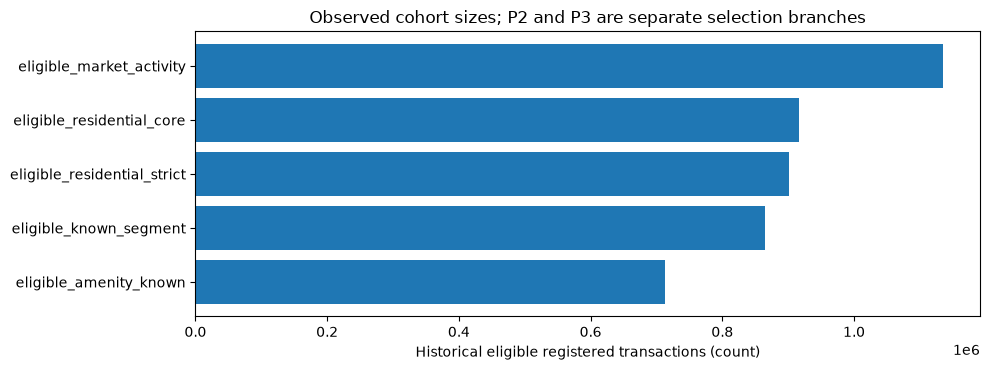

In [10]:
def selection_map():
    yr=source_dates.dt.year
    base=yr.between(2010,2025)
    rows=[]
    for c,parent in [('eligible_market_activity',None),('eligible_residential_core','eligible_market_activity'),
        ('eligible_residential_strict','eligible_residential_core'),('eligible_known_segment','eligible_residential_strict'),
        ('eligible_amenity_known','eligible_residential_strict')]:
        n=int((independent_flags[c]&base).sum())
        den=int((independent_flags[parent]&base).sum()) if parent else len(audit_df)
        rows.append(dict(cohort=c,parent=parent or 'source',n=n,parent_n=den,coverage_pct=_ratio(n,den),
                         denominator_note='P2 and P3 are parallel branches, not sequential stages'))
    return pd.DataFrame(rows)
selection=raw_result('06_integrated_population_selection',selection_map)
if not selection.empty:
    fig,ax=plt.subplots(figsize=(10,3.8));ax.barh(selection.cohort,selection.n)
    ax.set(xlabel='Historical eligible registered transactions (count)',title='Observed cohort sizes; P2 and P3 are separate selection branches')
    ax.invert_yaxis();fig.tight_layout();FIGURES.append(('06_cohort_selection.png',fig,'06_integrated_population_selection','Historical source; parent denominators in table'))
    plt.show()

## 03 — Equivalent-estimand cross-notebook consistency
Only compare numbers if **population, period, quantity, units, formula, weighting and treatment of missing categories are the same**. A raw transaction median cannot be checked by averaging community medians; an endpoint group index is not a repeat-sales index.

In [11]:
def attach_common_fields():
    if not DATA_OK:return
    audit_df['audit_year']=source_dates.dt.year.astype('Int64')
    numeric_price=pd.to_numeric(audit_df.price_aed,errors='coerce')
    numeric_area=pd.to_numeric(audit_df.area_sqm,errors='coerce')
    valid=np.isfinite(numeric_price)&np.isfinite(numeric_area)&numeric_price.gt(0)&numeric_area.gt(0)
    audit_df['audit_psm']=np.where(valid,numeric_price/numeric_area,np.nan)
    audit_df['audit_log_psm']=np.log(audit_df.audit_psm)
    audit_df['audit_log_price']=np.log(numeric_price.where(numeric_price.gt(0)))
    audit_df['audit_log_area']=np.log(numeric_area.where(numeric_area.gt(0)))
    for kind,bands in [('coarse',COARSE_AREA_BANDS_SQM),('fine',FINE_AREA_BANDS_SQM)]:
        vals=pd.Series(pd.NA,index=audit_df.index,dtype='string')
        for typ,edges in bands.items():
            ids=audit_df.property_type_label.eq(typ)
            labels=[f'{typ}:{i:02d}' for i in range(len(edges)-1)]
            vals.loc[ids]=pd.cut(numeric_area.loc[ids],bins=edges,labels=labels,include_lowest=False,right=True).astype('string')
        audit_df[f'audit_size_{kind}']=vals
attach_common_fields()
def frame_for(cohort,start=2010,end=2025):
    if not DATA_OK:return pd.DataFrame()
    return audit_df.loc[independent_flags[cohort] & audit_df.audit_year.between(start,end)]
print('Independent price/area/year and fixed-band views:', 'ready' if DATA_OK else 'withheld')

Independent price/area/year and fixed-band views: ready


In [12]:
def activity():
    h=frame_for('eligible_market_activity')
    return h.groupby('audit_year',observed=True).agg(n=('transaction_id','size'),
       registered_value_aed=('price_aed','sum')).reset_index().rename(columns={'audit_year':'year'})
activity_totals=raw_result('06_independent_activity_totals',activity,claims='RQ04')
if DATA_OK:
    check('MARKET','Activity counts sum to P0',int(activity_totals.n.sum())==len(frame_for('eligible_market_activity')),
          independence='A',critical=True,claims='RQ04')

06_independent_activity_totals: 16 rows, 3 columns


,year,n,registered_value_aed
0,2010,34120,63183813267
1,2011,28439,58208880289
2,2012,36479,73377228693
3,2013,64517,147218709427
4,2014,56018,140300595462
5,2015,42882,119959199993
6,2016,42692,109098986586
7,2017,46230,115763539276


In [13]:
def residential():
    h=frame_for('eligible_residential_strict')
    return h.groupby('audit_year',observed=True).agg(n=('transaction_id','size'),
        median_price_aed=('price_aed','median'),median_area_sqm=('area_sqm','median'),
        median_psm=('audit_psm','median'),p90_psm=('audit_psm',lambda z:z.quantile(.9))).reset_index().rename(columns={'audit_year':'year'})
residential_prices=raw_result('06_independent_residential_prices',residential,claims='RQ01,RQ02')
if DATA_OK:
    check('PRICING','All P1 pricing observations positive',frame_for('eligible_residential_strict').audit_psm.gt(0).all(),
          independence='A',claims='RQ01,RQ10',critical=True)

06_independent_residential_prices: 16 rows, 6 columns


,year,n,median_price_aed,median_area_sqm,median_psm,p90_psm
0,2010,27717,961677.0,90.36,9282.399143,17352.432113
1,2011,21945,1000000.0,111.67,8650.893986,15841.861891
2,2012,26113,1020000.0,104.81,9179.313715,15828.428606
3,2013,47400,1160000.0,98.44,9857.946524,19268.168605
4,2014,41323,1173888.0,90.87,10903.638151,21733.774563
5,2015,31581,1104361.0,91.92,10538.810519,20537.547995
6,2016,30762,1058556.5,90.82,10684.534589,19843.655991
7,2017,35267,1115000.0,93.00,10874.857978,19157.340355


In [14]:
def registration_shares():
    rows=[]
    for cohort in ['eligible_market_activity','eligible_residential_strict']:
        h=frame_for(cohort).copy();h['_reg']=registration_label(h.reg_type_label)
        g=h.groupby(['audit_year','_reg'],observed=True).agg(n=('transaction_id','size'),value_aed=('price_aed','sum')).reset_index()
        g['parent_n']=g.groupby('audit_year').n.transform('sum')
        g['share_pct']=100*g.n/g.parent_n;g['cohort']=cohort
        rows.append(g.rename(columns={'audit_year':'year','_reg':'registration'}))
    return pd.concat(rows,ignore_index=True)
registration_shares=raw_result('06_registration_share_reconciliation',registration_shares,claims='RQ05')
if DATA_OK:
    check('REGISTRATION','Category counts preserve unknowns',
          registration_shares.groupby(['cohort','year']).share_pct.sum().sub(100).abs().max()<1e-9,
          claims='RQ05',independence='A',critical=True)

06_registration_share_reconciliation: 64 rows, 7 columns


,year,registration,n,value_aed,parent_n,share_pct,cohort
0,2010,Off-Plan,10800,17589448632,34120,31.652989,eligible_market_activity
1,2010,Ready,23320,45594364635,34120,68.347011,eligible_market_activity
2,2011,Off-Plan,2746,3426862280,28439,9.655754,eligible_market_activity
3,2011,Ready,25693,54782018009,28439,90.344246,eligible_market_activity
4,2012,Off-Plan,4000,6825625035,36479,10.965213,eligible_market_activity
5,2012,Ready,32479,66551603658,36479,89.034787,eligible_market_activity
6,2013,Off-Plan,11713,22619482411,64517,18.154905,eligible_market_activity
7,2013,Ready,52804,124599227016,64517,81.845095,eligible_market_activity


In [15]:
def concentration():
    h=frame_for('eligible_market_activity').loc[lambda z:z.area_id.notna()]
    g=h.groupby(['audit_year','area_id'],observed=True).size().rename('n').reset_index()
    g['share']=g.n/g.groupby('audit_year').n.transform('sum')
    return g.assign(share_sq=g.share**2).groupby('audit_year').agg(
        count_hhi=('share_sq','sum'),known_n=('n','sum'),areas=('area_id','nunique'),
        largest_area_pct=('share',lambda x:100*x.max())).reset_index().rename(columns={'audit_year':'year'})
concentration_totals=raw_result('06_concentration_reconciliation',concentration,claims='RQ04')
if DATA_OK:check('GEO','HHI bounded',concentration_totals.count_hhi.between(0,1).all(),independence='A',claims='RQ04',critical=True)

06_concentration_reconciliation: 16 rows, 5 columns


,year,count_hhi,known_n,areas,largest_area_pct
0,2010,0.102432,34120,128,17.851700
1,2011,0.092837,28439,131,18.664510
2,2012,0.090600,36479,139,17.338743
3,2013,0.073328,64517,145,14.642652
4,2014,0.051409,56018,158,10.360955
5,2015,0.037487,42882,159,6.704445
6,2016,0.034739,42692,163,6.628877
7,2017,0.032605,46230,155,6.954359


In [16]:
def budget_tail():
    h=frame_for('eligible_residential_strict')
    rows=[]
    for yr,g in h.groupby('audit_year',observed=True):
        prices=g.price_aed.to_numpy(dtype=float);n=len(prices);t=prices.sum()
        for cut in NOMINAL_BUDGET_THRESHOLDS_AED:
            rows.append(dict(year=int(yr),metric='budget_leq',threshold_aed=int(cut),n=n,
               numerator=int((prices<=cut).sum()),denominator=n,value_pct=np.nan,
               share_pct=100*(prices<=cut).mean()))
        k=max(1,int(np.ceil(.1*n)));top=np.sort(prices)[-k:]
        rows.append(dict(year=int(yr),metric='top10pct_value_share',threshold_aed=np.nan,
            n=n,numerator=k,denominator=n,value_pct=100*top.sum()/t if t>0 else np.nan,share_pct=np.nan))
    return pd.DataFrame(rows)
budget_tail_totals=raw_result('06_budget_tail_reconciliation',budget_tail,claims='RQ03,RQ14')
if DATA_OK:
    b=budget_tail_totals.query('metric=="budget_leq"').sort_values(['year','threshold_aed'])
    check('BUDGET','Budget cumulative ordering',b.groupby('year').share_pct.apply(lambda z:z.is_monotonic_increasing).all(),claims='RQ03',independence='A',critical=True)

06_budget_tail_reconciliation: 64 rows, 8 columns


,year,metric,threshold_aed,n,numerator,denominator,value_pct,share_pct
0,2010,budget_leq,1000000.0,27717,14399,27717,NaN,51.950067
1,2010,budget_leq,1500000.0,27717,19442,27717,NaN,70.144677
2,2010,budget_leq,2000000.0,27717,22655,27717,NaN,81.736840
3,2010,top10pct_value_share,NaN,27717,2772,27717,30.467424,NaN
4,2011,budget_leq,1000000.0,21945,11016,21945,NaN,50.198223
5,2011,budget_leq,1500000.0,21945,15026,21945,NaN,68.471178
6,2011,budget_leq,2000000.0,21945,17609,21945,NaN,80.241513
7,2011,top10pct_value_share,NaN,21945,2195,21945,31.446828,NaN


## 04 — RQ01/RQ02 independently reconstructed price and size composition
Designs A–E and Unit/Villa physical size bands are imported from the approved project config. The main verification independently aggregates transaction medians within eligible endpoint groups; weights are fixed to the 2021 matched-basket distribution. Each different design estimates a different selected population.

In [17]:
# Independent endpoint matching implementation (does not call src.statistics).
def index_matched(design,threshold=30,weight_mode='base'):
    data=frame_for('eligible_residential_strict',2021,2025)
    if data.empty:return None,pd.DataFrame()
    cols=[('audit_size_coarse' if k=='size_coarse' else 'audit_size_fine' if k=='size_fine' else k) for k in MATCHING_DESIGNS[design]]
    h=data.loc[data.audit_year.isin([2021,2025])].dropna(subset=cols).copy()
    if 'rooms_bucket' in MATCHING_DESIGNS[design]:
        h=h.loc[pd.to_numeric(h.rooms_bucket,errors='coerce').isin(range(6))]
    g=h.groupby(cols+['audit_year'],observed=True).agg(n=('transaction_id','size'),med=('audit_psm','median'),
       mean_log_psm=('audit_log_psm','mean'),mean_log_area=('audit_log_area','mean')).reset_index()
    a=g.loc[g.audit_year.eq(2021)].drop(columns='audit_year').rename(columns={c:c+'_base' for c in ['n','med','mean_log_psm','mean_log_area']})
    b=g.loc[g.audit_year.eq(2025)].drop(columns='audit_year').rename(columns={c:c+'_end' for c in ['n','med','mean_log_psm','mean_log_area']})
    matched=a.merge(b,on=cols,validate='one_to_one')
    matched=matched.loc[matched.n_base.ge(threshold)&matched.n_end.ge(threshold)].copy()
    if matched.empty:return None,pd.DataFrame()
    n0=matched.n_base.to_numpy(float);n1=matched.n_end.to_numpy(float)
    if weight_mode=='base':w=n0/n0.sum()
    elif weight_mode=='end':w=n1/n1.sum()
    elif weight_mode=='symmetric':w=.5*n0/n0.sum()+.5*n1/n1.sum()
    elif weight_mode=='equal':w=np.repeat(1/len(matched),len(matched))
    else:raise ValueError('Unknown weight mode')
    lr=np.log(matched.med_end.to_numpy(float)/matched.med_base.to_numpy(float));delta=float(w@lr)
    matched['weight']=w;matched['log_change']=lr;matched['weighted_contribution']=w*lr
    parent0=int(data.audit_year.eq(2021).sum());parent1=int(data.audit_year.eq(2025).sum())
    r=dict(design=design,threshold=threshold,weight_mode=weight_mode,matched_cells=len(matched),
        n_2021=int(n0.sum()),n_2025=int(n1.sum()),parent_2021=parent0,parent_2025=parent1,
        coverage_2021_pct=_ratio(int(n0.sum()),parent0),coverage_2025_pct=_ratio(int(n1.sum()),parent1),
        log_change=delta,change_pct=100*np.expm1(delta),effective_segments=1/float(w@w))
    assert _close(matched.weight.sum(),1,atol=1e-12)
    assert _close(matched.weighted_contribution.sum(),delta,atol=1e-12)
    return r,matched

price_matching_rows=[]; PRICE_DETAILS={}
if DATA_OK:
    for design in MATCHING_DESIGNS:
        for t in (20,30,50):
            result,detail=index_matched(design,t)
            if result:price_matching_rows.append(result)
            if t==30 and not detail.empty:PRICE_DETAILS[design]=detail
price_matching=expose('06_price_matching_feasibility',pd.DataFrame(price_matching_rows))

06_price_matching_feasibility: 15 rows, 13 columns


,design,threshold,weight_mode,matched_cells,n_2021,n_2025,parent_2021,parent_2025,coverage_2021_pct,coverage_2025_pct,log_change,change_pct,effective_segments
0,A_broad,20,base,108,45257,128660,46302,178962,97.743078,71.892357,0.498489,64.623247,39.304114
1,A_broad,30,base,102,45119,123661,46302,178962,97.445035,69.099027,0.499604,64.806811,39.067201
2,A_broad,50,base,87,43569,120651,46302,178962,94.097447,67.417105,0.498936,64.696800,36.660650
3,B_bedrooms,20,base,233,40222,106754,46302,178962,86.868818,59.651770,0.481925,61.918900,92.231330
4,B_bedrooms,30,base,200,38525,103902,46302,178962,83.203749,58.058135,0.482167,61.958029,85.928426
5,B_bedrooms,50,base,156,35988,88683,46302,178962,77.724504,49.554095,0.476690,61.073446,76.577692
6,C_size_only,20,base,303,39717,101893,46302,178962,85.778152,56.935551,0.478004,61.285245,128.218485
7,C_size_only,30,base,248,37556,87951,46302,178962,81.110967,49.145070,0.475460,60.875411,116.627715


In [18]:
price_index_independent=expose('06_price_index_independent',
    price_matching.loc[price_matching.threshold.eq(30)].copy() if not price_matching.empty else pd.DataFrame())
price_export=load_export('02','price_index_endpoint',required=DATA_OK,claims='RQ01')
if DATA_OK and not price_index_independent.empty:
    check('RQ01','Fixed 2021 weighted log change reconcilable',
          price_index_independent.change_pct.eq(100*np.expm1(price_index_independent.log_change)).all(),
          independence='A',claims='RQ01',critical=True)
    if not price_export.empty and {'design','change_pct'}.issubset(price_export):
        cmp=price_index_independent[['design','change_pct']].merge(price_export[['design','change_pct']],on='design',suffixes=('_independent','_upstream'))
        cmp['abs_diff_pp']=(cmp.change_pct_independent-cmp.change_pct_upstream).abs()
        COMPARES.extend([dict(rq='RQ01',metric=z.design,abs_diff=float(z.abs_diff_pp),units='percentage points',
             result='PASS' if z.abs_diff_pp<1e-6 else 'DISCREPANCY') for z in cmp.itertuples()])
        check('RQ01','Independent price indices vs exported 02',len(cmp)==len(price_index_independent) and cmp.abs_diff_pp.max()<1e-6,
              details=cmp[['design','abs_diff_pp']].to_dict('records'),independence='A',claims='RQ01',critical=True)

06_price_index_independent: 5 rows, 13 columns


,design,threshold,weight_mode,matched_cells,n_2021,n_2025,parent_2021,parent_2025,coverage_2021_pct,coverage_2025_pct,log_change,change_pct,effective_segments
1,A_broad,30,base,102,45119,123661,46302,178962,97.445035,69.099027,0.499604,64.806811,39.067201
4,B_bedrooms,30,base,200,38525,103902,46302,178962,83.203749,58.058135,0.482167,61.958029,85.928426
7,C_size_only,30,base,248,37556,87951,46302,178962,81.110967,49.145070,0.475460,60.875411,116.627715
10,D_size_bedrooms,30,base,250,32387,77258,46302,178962,69.947302,43.170058,0.469070,59.850664,114.153818
13,E_fine_bedrooms,30,base,263,28935,61731,46302,178962,62.491901,34.493915,0.470212,60.033272,122.780430


In [19]:
def decomposition(design='A_broad'):
    d=PRICE_DETAILS.get(design,pd.DataFrame())
    if d.empty:return pd.DataFrame()
    result=[]
    for topic in ['mean_log_psm','mean_log_area']:
        m0=d[f'{topic}_base'].to_numpy(float);m1=d[f'{topic}_end'].to_numpy(float)
        n0=d.n_base.to_numpy(float);n1=d.n_end.to_numpy(float)
        s0=n0/n0.sum();s1=n1/n1.sum()
        before=float(s0@m0);after=float(s1@m1)
        within=float((.5*(s1+s0))@(m1-m0));composition=float((.5*(m1+m0))@(s1-s0))
        result.append(dict(design=design,variable=topic,base_mean_log=before,end_mean_log=after,
              total_log_change=after-before,within_log_change=within,composition_log_change=composition,
              identity_residual=after-before-within-composition,matched_groups=len(d)))
    return pd.DataFrame(result)
price_decomposition=raw_result('06_price_decomposition_reconciliation',decomposition,claims='RQ01,RQ02')
if not price_decomposition.empty:
    check('RQ01','Price decomposition algebra',price_decomposition.identity_residual.abs().max()<1e-10,
        independence='C',claims='RQ01,RQ02',critical=True)

06_price_decomposition_reconciliation: 2 rows, 9 columns


,design,variable,base_mean_log,end_mean_log,total_log_change,within_log_change,composition_log_change,identity_residual,matched_groups
0,A_broad,mean_log_psm,9.335598,9.778102,0.442503,0.510535,-0.068032,8.604228e-16,102
1,A_broad,mean_log_area,4.692524,4.396695,-0.295829,-0.037921,-0.257908,2.775558e-16,102


In [20]:
area_decomposition=expose('06_area_decomposition_reconciliation',
    price_decomposition.loc[price_decomposition.variable.eq('mean_log_area')].copy() if not price_decomposition.empty else pd.DataFrame())
if not area_decomposition.empty:
    check('RQ02','Area is not the median-area estimand',
          area_decomposition.variable.eq('mean_log_area').all(),
          'The decomposition uses matched group mean-log area, not raw median area',claims='RQ02',independence='C')

06_area_decomposition_reconciliation: 1 rows, 9 columns


,design,variable,base_mean_log,end_mean_log,total_log_change,within_log_change,composition_log_change,identity_residual,matched_groups
1,A_broad,mean_log_area,4.692524,4.396695,-0.295829,-0.037921,-0.257908,2.775558e-16,102


In [21]:
price_windows=[]
if DATA_OK:
    h=frame_for('eligible_residential_strict',2019,2025)
    keys=['area_id','property_type_label','reg_type_label']
    for base_year in (2019,2020,2021,2022):
        sub=h.loc[h.audit_year.isin([base_year,2025])].copy()
        stats=sub.groupby(keys+['audit_year'],observed=True).agg(n=('transaction_id','size'),p=('audit_psm','median')).reset_index()
        a=stats.loc[stats.audit_year.eq(base_year)].drop(columns='audit_year').rename(columns={'n':'n0','p':'p0'})
        b=stats.loc[stats.audit_year.eq(2025)].drop(columns='audit_year').rename(columns={'n':'n1','p':'p1'})
        m=a.merge(b,on=keys);m=m.loc[m.n0.ge(30)&m.n1.ge(30)]
        if m.empty:continue
        w=m.n0.to_numpy(float);w/=w.sum()
        delta=float(w@np.log(m.p1.to_numpy(float)/m.p0.to_numpy(float)))
        price_windows.append(dict(base_year=base_year,end_year=2025,matched_cells=len(m),change_pct=100*np.expm1(delta),
          coverage_base_pct=_ratio(int(m.n0.sum()),int(sub.audit_year.eq(base_year).sum())),
          coverage_end_pct=_ratio(int(m.n1.sum()),int(sub.audit_year.eq(2025).sum()))))
price_time_sensitivity=expose('06_price_time_window_sensitivity',pd.DataFrame(price_windows))

06_price_time_window_sensitivity: 4 rows, 6 columns


,base_year,end_year,matched_cells,change_pct,coverage_base_pct,coverage_end_pct
0,2019,2025,91,76.814465,97.544111,71.596205
1,2020,2025,93,80.761746,97.172591,75.384719
2,2021,2025,102,64.806811,97.445035,69.099027
3,2022,2025,110,42.064376,98.221072,74.606341


In [22]:
price_policy=[]
if DATA_OK:
    for d in MATCHING_DESIGNS:
        for threshold in (20,30,50):
            for weights in ('base','end','equal'):
                x,_=index_matched(d,threshold,weights)
                if x:price_policy.append(x)
price_specification_sensitivity=expose('06_price_specification_sensitivity',pd.DataFrame(price_policy))
if not price_specification_sensitivity.empty:
    check('RQ01','Every supported price index has finite weights & coverage',
          np.isfinite(price_specification_sensitivity.change_pct).all() and price_specification_sensitivity.coverage_2025_pct.between(0,100).all(),
          claims='RQ01',independence='A',critical=True)

06_price_specification_sensitivity: 45 rows, 13 columns


,design,threshold,weight_mode,matched_cells,n_2021,n_2025,parent_2021,parent_2025,coverage_2021_pct,coverage_2025_pct,log_change,change_pct,effective_segments
0,A_broad,20,base,108,45257,128660,46302,178962,97.743078,71.892357,0.498489,64.623247,39.304114
1,A_broad,20,end,108,45257,128660,46302,178962,97.743078,71.892357,0.496504,64.296664,32.416303
2,A_broad,20,equal,108,45257,128660,46302,178962,97.743078,71.892357,0.489202,63.101352,108.000000
3,A_broad,30,base,102,45119,123661,46302,178962,97.445035,69.099027,0.499604,64.806811,39.067201
4,A_broad,30,end,102,45119,123661,46302,178962,97.445035,69.099027,0.513528,67.117649,31.108108
5,A_broad,30,equal,102,45119,123661,46302,178962,97.445035,69.099027,0.511571,66.790938,102.000000
6,A_broad,50,base,87,43569,120651,46302,178962,94.097447,67.417105,0.498936,64.696800,36.660650
7,A_broad,50,end,87,43569,120651,46302,178962,94.097447,67.417105,0.512745,66.986826,29.751773


In [23]:
def policy_decision(df,claims,description):
    if not DATA_OK:return dict(rq=claims,decision='BLOCKED',reason='Frozen source could not be recomputed')
    if df.empty:return dict(rq=claims,decision='NOT ESTIMABLE',reason='No supported strata')
    return dict(rq=claims,decision='QUALIFIED',reason=description)
price_decisions=expose('06_price_composition_decisions',pd.DataFrame([
    policy_decision(price_index_independent,'RQ01','Numerically reconstructed only for matched observed transactions; no repeat-sales identity'),
    policy_decision(area_decomposition,'RQ02','Common-support log-area decomposition; distinct from raw medians')]))

06_price_composition_decisions: 2 rows, 3 columns


,rq,decision,reason
0,RQ01,QUALIFIED,Numerically reconstructed only for matched obs...
1,RQ02,QUALIFIED,Common-support log-area decomposition; distinc...


## 05 — Registered activity, registration composition, lead–lag and upper tails
**RQ04/RQ05** permit exact additivity of mutually exclusive activity counts. **RQ06** needs genuine out-of-time replication and leakage diagnostics; a stored predictive score alone is not sufficient. **RQ14** is a distribution of recorded consideration, not market value or investor wealth.

In [24]:
def activity_bridge():
    t=activity_totals.set_index('year');a=t.loc[2021];b=t.loc[2025]
    return pd.DataFrame([dict(base_year=2021,end_year=2025,n_start=int(a.n),n_end=int(b.n),
        delta_n=int(b.n-a.n),value_start=float(a.registered_value_aed),value_end=float(b.registered_value_aed),
        delta_registered_value_aed=float(b.registered_value_aed-a.registered_value_aed))])
activity_growth=raw_result('06_activity_growth_reconciliation',activity_bridge,claims='RQ04')

06_activity_growth_reconciliation: 1 rows, 8 columns


,base_year,end_year,n_start,n_end,delta_n,value_start,value_end,delta_registered_value_aed
0,2021,2025,59424,214803,155379,1.483502e+11,6.823304e+11,5.339802e+11


In [25]:
def registration_growth():
    h=registration_shares.loc[(registration_shares.cohort=='eligible_market_activity') & registration_shares.year.isin([2021,2025])]
    g=h.pivot(index='registration',columns='year',values='n').fillna(0)
    g=g.reindex(columns=[2021,2025],fill_value=0)
    out=g.rename(columns={2021:'n_2021',2025:'n_2025'}).reset_index()
    out['delta_n']=out.n_2025-out.n_2021
    return out
registration_growth_bridge=raw_result('06_registration_growth_reconciliation',registration_growth,claims='RQ05')
if DATA_OK and not activity_growth.empty:
    check('RQ05','Registration 2021–25 bridge',int(registration_growth_bridge.delta_n.sum())==int(activity_growth.delta_n.iloc[0]),
          claims='RQ05',independence='A',critical=True)

06_registration_growth_reconciliation: 2 rows, 4 columns


year,registration,n_2021,n_2025,delta_n
0,Off-Plan,23375,134384,111009
1,Ready,36049,80419,44370


In [26]:
def geographic_universe():
    h=frame_for('eligible_market_activity').loc[lambda x:x.audit_year.isin([2021,2025]) & x.area_id.notna()]
    counts=h.groupby(['area_id','audit_year'],observed=True).size().unstack('audit_year',fill_value=0).reindex(columns=[2021,2025],fill_value=0)
    sets={'all_known':counts.index,'common_active':counts.loc[counts.gt(0).all(axis=1)].index}
    rows=[]
    for kind,ids in sets.items():
        for year in [2021,2025]:
            n=counts.loc[ids,year].to_numpy(float); s=n/n.sum() if n.sum()>0 else np.array([])
            rows.append(dict(universe=kind,year=year,communities=len(ids),n=int(n.sum()),hhi=float(np.square(s).sum()) if len(s) else np.nan))
    return pd.DataFrame(rows)
geographic_sensitivity=raw_result('06_geographic_universe_sensitivity',geographic_universe,claims='RQ04')

06_geographic_universe_sensitivity: 4 rows, 5 columns


,universe,year,communities,n,hhi
0,all_known,2021,177,59424,0.042678
1,all_known,2025,177,214803,0.031983
2,common_active,2021,147,58436,0.043992
3,common_active,2025,147,207924,0.033605


In [27]:
def leakage_review():
    nb=UPSTREAM_NBS.get('03')
    if nb is None:return pd.DataFrame([dict(item='Notebook 03 available',status='BLOCKED',details='No executed Notebook 03')])
    code='\n'.join(''.join(c.get('source',[])) for c in nb['cells'] if c['cell_type']=='code')
    indicators={
      'explicit chronological fold construction':bool(re.search(r'TimeSeriesSplit|train_year|train_end|train_mask|fold',code,re.I)),
      'future target / lead shift audited':bool(re.search(r'shift\s*\(\s*-|future|lead',code,re.I)),
      'point-in-time feature provenance verified':False,
    }
    rows=[dict(item=k,status='OBSERVED_CODE_PATTERN' if v else 'NOT_VERIFIED',details='Pattern presence is not a statistical leakage clearance') for k,v in indicators.items()]
    return pd.DataFrame(rows)
lead_lag_leakage=expose('06_lead_lag_leakage_audit',leakage_review())
issue('RQ06','POINT_IN_TIME_SOURCE_LIMITATION','QUALIFIED','Publisher flags and whole-snapshot derived variables may not be point-in-time available; original out-of-time folds require separate recreation','RQ06')

06_lead_lag_leakage_audit: 3 rows, 3 columns


,item,status,details
0,explicit chronological fold construction,OBSERVED_CODE_PATTERN,Pattern presence is not a statistical leakage ...
1,future target / lead shift audited,OBSERVED_CODE_PATTERN,Pattern presence is not a statistical leakage ...
2,point-in-time feature provenance verified,NOT_VERIFIED,Pattern presence is not a statistical leakage ...


In [28]:
def leadlag_review():
    base=load_export('03','activity_lead_lag_validation',required=True,claims='RQ06')
    if base.empty:
        return pd.DataFrame([dict(rq='RQ06',status='INCONCLUSIVE',independence='D',
            detail='No accessible complete fold-level predictive export; no independent forward-looking claim')])
    return pd.DataFrame([dict(rq='RQ06',status='INCONCLUSIVE',independence='D',
            detail=f'{len(base)} exported rows inspected; independent chronological fold recreation not established')])
lead_lag_independent=expose('06_lead_lag_independent_validation',leadlag_review())

06_lead_lag_independent_validation: 1 rows, 4 columns


,rq,status,independence,detail
0,RQ06,INCONCLUSIVE,D,2 exported rows inspected; independent chronol...


In [29]:
market_activity_decisions=expose('06_market_activity_decisions',pd.DataFrame([
    dict(rq='RQ03',decision='QUALIFIED' if DATA_OK and not budget_tail_totals.empty else 'BLOCKED',restriction='Nominal registered-price budgets only'),
    dict(rq='RQ04',decision='SUPPORTED' if DATA_OK and not activity_growth.empty and not geographic_sensitivity.empty else 'BLOCKED',restriction='Registered-activity accounting only, not housing demand'),
    dict(rq='RQ05',decision='SUPPORTED' if DATA_OK and not registration_growth_bridge.empty else 'BLOCKED',restriction='Registration labels are not equivalent sales/financing processes'),
    dict(rq='RQ06',decision='INCONCLUSIVE' if '03' in UPSTREAM_NBS else 'BLOCKED',restriction='No verified robust incremental predictive value'),
    dict(rq='RQ14',decision='QUALIFIED' if DATA_OK and not budget_tail_totals.empty else 'BLOCKED',restriction='Registered transaction value distribution, not investment return')
]))

06_market_activity_decisions: 5 rows, 3 columns


,rq,decision,restriction
0,RQ03,QUALIFIED,Nominal registered-price budgets only
1,RQ04,SUPPORTED,"Registered-activity accounting only, not housi..."
2,RQ05,SUPPORTED,Registration labels are not equivalent sales/f...
3,RQ06,INCONCLUSIVE,No verified robust incremental predictive value
4,RQ14,QUALIFIED,"Registered transaction value distribution, not..."


## 06 — Community research (RQ07, RQ08, RQ09, RQ13)
Independent verification must respect the **203 observed community IDs**, the **34 eligible RQ07 community growth estimates**, and the restrictions on selected submarkets. Unobserved prices must never be imputed into missing years; community ID is not a stable physical-boundary guarantee.

In [30]:
def identities():
    h=frame_for('eligible_market_activity');g=h.loc[h.area_id.notna()]
    pair=g[['area_id','area_name_en']].drop_duplicates()
    c1=pair.groupby('area_id').area_name_en.nunique(dropna=True)
    return pd.DataFrame([dict(observed_ids=g.area_id.nunique(),source_known_n=len(g),
        source_unknown_n=len(h)-len(g),ids_with_multiple_labels=int(c1.gt(1).sum()))])
community_identity=raw_result('06_community_identity_audit',identities,claims='RQ07,RQ08,RQ09,RQ13')

06_community_identity_audit: 1 rows, 4 columns


,observed_ids,source_known_n,source_unknown_n,ids_with_multiple_labels
0,203,1134513,0,0


In [31]:
def community_eligibility():
    strict=frame_for('eligible_residential_strict').loc[lambda x:x.audit_year.isin([2021,2025])&x.area_id.notna()]
    p0=frame_for('eligible_market_activity')
    areas=sorted(p0.area_id.dropna().unique().tolist())
    parent=(strict.groupby(['area_id','audit_year'],observed=True).size().unstack('audit_year',fill_value=0)
            .reindex(index=areas,columns=[2021,2025],fill_value=0))
    # Independent group counts; P1 strict is the parent population for A and C.
    rows=[]
    for design in ('A_broad','C_size_only'):
        cols=['area_id','property_type_label','reg_type_label']+(['audit_size_coarse'] if design=='C_size_only' else [])
        data=strict.loc[strict.reg_type_label.isin(['Ready','Off-Plan'])].dropna(subset=cols)
        counts=data.groupby(cols+['audit_year'],observed=True).size().rename('n').reset_index()
        a=counts.loc[counts.audit_year.eq(2021)].drop(columns='audit_year').rename(columns={'n':'n0'})
        b=counts.loc[counts.audit_year.eq(2025)].drop(columns='audit_year').rename(columns={'n':'n1'})
        supported=a.merge(b,on=cols,validate='one_to_one')
        supported=supported.loc[supported.n0.ge(30)&supported.n1.ge(30)]
        for area in areas:
            g=supported.loc[supported.area_id.eq(area)]
            n0=int(g.n0.sum());n1=int(g.n1.sum());par0=int(parent.loc[area,2021]);par1=int(parent.loc[area,2025])
            w=g.n0.to_numpy(float)/n0 if n0>0 else np.array([])
            eff=1/float(w@w) if len(w) else 0
            okay=par0>=100 and par1>=100 and len(g)>=2 and _ratio(n0,par0)>=50 and _ratio(n1,par1)>=50 and eff>=1.5
            rows.append(dict(area_id=area,design=design,p1_2021_n=par0,p1_2025_n=par1,
                matched_2021_n=n0,matched_2025_n=n1,matched_groups=len(g),
                coverage_2021_pct=_ratio(n0,par0),coverage_2025_pct=_ratio(n1,par1),
                effective_groups=eff,passes_community_gate=bool(okay)))
    t=pd.DataFrame(rows)
    c=t.pivot(index='area_id',columns='design',values='passes_community_gate').fillna(False)
    t['selected_design']=t.area_id.map({area:('C_size_only' if z.get('C_size_only',False) else 'A_broad' if z.get('A_broad',False) else 'NONE') for area,z in c.iterrows()})
    t['matched_price_eligible']=t.selected_design.ne('NONE')
    return t
community_eligibility=raw_result('06_community_eligibility_reconciliation',community_eligibility,claims='RQ07')
if DATA_OK and not community_eligibility.empty:
    upstream=load_export('04','matching_decisions',required=True,claims='RQ07')
    local=community_eligibility.drop_duplicates('area_id')[['area_id','selected_design','matched_price_eligible']]
    if not upstream.empty and {'area_key','selected_design','matched_price_eligible'}.issubset(upstream):
        comp=local.merge(upstream[['area_key','selected_design','matched_price_eligible']],left_on='area_id',right_on='area_key',suffixes=('_ind','_up'),validate='one_to_one')
        same=len(comp)==len(local)==len(upstream) and comp.selected_design_ind.astype(str).eq(comp.selected_design_up.astype(str)).all() and comp.matched_price_eligible_ind.astype(bool).eq(comp.matched_price_eligible_up.astype(bool)).all()
        check('RQ07','Independent exact Notebook04 community eligibility',same,claims='RQ07',critical=True,independence='A')
    else:check('RQ07','Upstream community eligibility accessible',False,
               'Without the complete upstream eligibility export, 34/203 cannot be independently certified',claims='RQ07',critical=True,independence='D')

06_community_eligibility_reconciliation: 406 rows, 13 columns


,area_id,design,p1_2021_n,p1_2025_n,matched_2021_n,matched_2025_n,matched_groups,coverage_2021_pct,coverage_2025_pct,effective_groups,passes_community_gate,selected_design,matched_price_eligible
0,230.0,A_broad,10,25,0,0,0,0.0,0.0,0.000000,False,NONE,False
1,231.0,A_broad,4,6,0,0,0,0.0,0.0,0.000000,False,NONE,False
2,232.0,A_broad,163,261,163,261,3,100.0,100.0,2.936126,True,A_broad,True
3,233.0,A_broad,18,35,0,0,0,0.0,0.0,0.000000,False,NONE,False
4,234.0,A_broad,3,3,0,0,0,0.0,0.0,0.000000,False,NONE,False
5,235.0,A_broad,0,0,0,0,0,NaN,NaN,0.000000,False,NONE,False
6,237.0,A_broad,0,0,0,0,0,NaN,NaN,0.000000,False,NONE,False
7,238.0,A_broad,0,0,0,0,0,NaN,NaN,0.000000,False,NONE,False


In [32]:
def independent_community_spotcheck():
    d=PRICE_DETAILS.get('A_broad',pd.DataFrame())
    if d.empty:return pd.DataFrame()
    candidates=d.groupby('area_id').agg(base_n=('n_base','sum'),end_n=('n_end','sum'),groups=('weight','size')).sort_values('base_n',ascending=False)
    chosen=list(candidates.head(3).index)+list(candidates.tail(3).index)
    rows=[]
    for community in dict.fromkeys(chosen):
        local=d.loc[d.area_id.eq(community)]
        w=local.n_base.to_numpy(float);w/=w.sum()
        delta=float(w@np.log(local.med_end.to_numpy(float)/local.med_base.to_numpy(float)))
        rows.append(dict(area_id=community,groups=len(local),base_n=int(local.n_base.sum()),end_n=int(local.n_end.sum()),
                         separately_reweighted_change_pct=100*np.expm1(delta),
                         caveat='Audits group medians on selected supported broad cells; not necessarily Notebook 04 community estimator'))
    return pd.DataFrame(rows)
community_growth_checks=raw_result('06_community_growth_independent_checks',independent_community_spotcheck,claims='RQ07')

06_community_growth_independent_checks: 6 rows, 6 columns


,area_id,groups,base_n,end_n,separately_reweighted_change_pct,caveat
0,330.0,2,5456,6556,44.136570,Audits group medians on selected supported bro...
1,526.0,2,3908,11499,58.616232,Audits group medians on selected supported bro...
2,441.0,3,3231,17701,67.272024,Audits group medians on selected supported bro...
3,437.0,1,33,75,81.606988,Audits group medians on selected supported bro...
4,459.0,1,32,188,54.321120,Audits group medians on selected supported bro...
5,443.0,1,31,105,50.730088,Audits group medians on selected supported bro...


In [33]:
def dispersion():
    h=frame_for('eligible_residential_strict',2021,2025)
    h=h.loc[h.property_type_label.eq('Unit') & h.reg_type_label.isin(['Ready','Off-Plan']) & h.area_id.notna()]
    g=h.groupby(['reg_type_label','audit_size_coarse','area_id','audit_year'],observed=True).agg(n=('transaction_id','size'),med=('audit_psm','median')).reset_index()
    endpoints=g.pivot_table(index=['reg_type_label','audit_size_coarse','area_id'],columns='audit_year',values='n',aggfunc='sum',fill_value=0)
    endpoints=endpoints.reindex(columns=[2021,2025],fill_value=0);allowed=endpoints.loc[endpoints.ge(30).all(axis=1)].reset_index()
    if allowed.empty:return pd.DataFrame()
    score=allowed.groupby(['reg_type_label','audit_size_coarse'],observed=True).area_id.nunique().reset_index(name='communities')
    score=score.sort_values(['communities','reg_type_label','audit_size_coarse'],ascending=[False,True,True])
    best=score.iloc[0];reg,band=best.reg_type_label,best.audit_size_coarse
    areas=set(allowed.loc[allowed.reg_type_label.eq(reg)&allowed.audit_size_coarse.eq(band),'area_id'])
    chosen=g.loc[g.reg_type_label.eq(reg)&g.audit_size_coarse.eq(band)&g.area_id.isin(areas)&g.audit_year.isin([2021,2025])]
    out=[]
    for y,sub in chosen.groupby('audit_year'):
        x=np.log(sub.med.to_numpy(float))
        out.append(dict(year=int(y),registration=reg,size_band=band,eligible_communities=len(areas),
                        sd_log_medians=float(x.std(ddof=1)),log_p90_p10=float(np.quantile(x,.9)-np.quantile(x,.1))))
    return pd.DataFrame(out)
community_dispersion=raw_result('06_community_dispersion_validation',dispersion,claims='RQ08')

06_community_dispersion_validation: 2 rows, 6 columns


,year,registration,size_band,eligible_communities,sd_log_medians,log_p90_p10
0,2021,Ready,Unit:02,26,0.428421,1.086157
1,2025,Ready,Unit:02,26,0.390357,0.956082


In [34]:
def regimes():
    ref=load_export('04','activity_price_regimes',required=True,claims='RQ09')
    if ref.empty:return pd.DataFrame([dict(status='BLOCKED',reason='Missing original regime result')])
    needed={'area_key','change_pct','strict_count_change','ci_low_pct','ci_high_pct','regime'}
    if not needed.issubset(ref):
        issue('RQ09','REGIME_SCHEMA','BLOCKED',f'Missing {needed-set(ref.columns)}','RQ09')
        return pd.DataFrame([dict(status='BLOCKED',reason='Upstream regime columns insufficient')])
    r=ref.copy()
    expected=np.select([r.change_pct.isna(),
        r.change_pct.gt(0)&r.strict_count_change.gt(0),
        r.change_pct.gt(0)&r.strict_count_change.lt(0),
        r.change_pct.lt(0)&r.strict_count_change.gt(0),
        r.change_pct.lt(0)&r.strict_count_change.lt(0)],
        ['NOT ESTIMABLE','count up / matched price up','count down / matched price up',
        'count up / matched price down','count down / matched price down'],default='ZERO OR AMBIGUOUS')
    uncertain=r.change_pct.notna()&(r.ci_low_pct.isna()|r.ci_high_pct.isna()|
        ((r.ci_low_pct<=0)&(r.ci_high_pct>=0)))
    expected[uncertain]='UNCERTAIN CONDITIONAL PRICE SIGN'
    correct=np.asarray(expected,dtype=str)==r.regime.astype(str).to_numpy()
    # Independent price-sign rule only; upstream growth magnitudes remain model-restricted.
    check('RQ09','Independent regime sign/CI classification',correct.all(),
        f'{correct.sum()}/{len(correct)} labels reconstruct',independence='B',claims='RQ09',critical=True)
    return pd.DataFrame([dict(status='CLASSIFICATION_VERIFIED' if correct.all() else 'BLOCKED',n_rows=len(r),
             matched_label_n=int(correct.sum()),reason='Descriptive count/price quadrant; not measured liquidity')])
community_regimes=expose('06_community_regime_reconciliation',regimes())

06_community_regime_reconciliation: 1 rows, 4 columns


,status,n_rows,matched_label_n,reason
0,CLASSIFICATION_VERIFIED,203,203,Descriptive count/price quadrant; not measured...


In [35]:
def stability():
    r=load_export('04','price_stability',required=True,claims='RQ13')
    if r.empty:return pd.DataFrame([dict(status='BLOCKED',reason='Community stability series not available')])
    needed=['first_link','last_link','eligible_links']
    if not set(needed).issubset(r):
        issue('RQ13','STABILITY_SCHEMA','BLOCKED',f'Missing {set(needed)-set(r)}','RQ13')
        return pd.DataFrame([dict(status='BLOCKED',reason='Series continuity fields absent')])
    valid=(pd.to_numeric(r.last_link,errors='coerce')-pd.to_numeric(r.first_link,errors='coerce')+1==pd.to_numeric(r.eligible_links,errors='coerce'))
    check('RQ13','All exported stability histories are consecutive',valid.all(),independence='D',claims='RQ13',critical=True)
    return pd.DataFrame([dict(status='CONTINUITY_AUDITED',histories=len(r),valid_histories=int(valid.sum()),
                              claim='Observed matched-group chains, not investment returns')])
community_stability=expose('06_community_stability_validation',stability())

06_community_stability_validation: 1 rows, 4 columns


,status,histories,valid_histories,claim
0,CONTINUITY_AUDITED,66,66,"Observed matched-group chains, not investment ..."


In [36]:
community_research_decisions=expose('06_community_research_decisions',pd.DataFrame([
    dict(rq='RQ07',decision='QUALIFIED' if DATA_OK and not community_growth_checks.empty else 'BLOCKED',
         reason='Selected supported community baskets; upstream detailed eligibility must independently reconcile'),
    dict(rq='RQ08',decision='QUALIFIED' if DATA_OK and len(community_dispersion)==2 else 'BLOCKED',
         reason='Fixed endpoint submarket only; between-community transaction median levels'),
    dict(rq='RQ09',decision='QUALIFIED' if not community_regimes.empty and community_regimes.status.iloc[0]=='CLASSIFICATION_VERIFIED' else 'BLOCKED',
         reason='Descriptive regimes; not market liquidity'),
    dict(rq='RQ13',decision='QUALIFIED' if not community_stability.empty and community_stability.status.iloc[0]=='CONTINUITY_AUDITED' else 'BLOCKED',
         reason='Supported consecutive links; not investor-return volatility')
]))

06_community_research_decisions: 4 rows, 3 columns


,rq,decision,reason
0,RQ07,QUALIFIED,Selected supported community baskets; upstream...
1,RQ08,QUALIFIED,Fixed endpoint submarket only; between-communi...
2,RQ09,QUALIFIED,Descriptive regimes; not market liquidity
3,RQ13,QUALIFIED,Supported consecutive links; not investor-retu...


## 07 — Market-structure independent validation (RQ10–RQ12)
The flagship RQ11 estimand is a **within-supported-cell, pooled-weight difference in mean log AED/sqm**, Off-Plan minus Ready. It is not a contemporaneous *median index*, a causal premium, a Ready resale comparison, or interchangeable with a fixed-effects weighted estimator. Report all matched samples and missing-bedroom exclusions.

In [37]:
def registration_gap_independent(threshold=30):
    h=frame_for('eligible_known_segment',2020,2025)
    keys=['area_id','audit_year','property_type_label','rooms_bucket','audit_size_coarse']
    h=h.loc[h.reg_type_label.isin(['Ready','Off-Plan'])].dropna(subset=keys)
    g=h.groupby(keys+['reg_type_label'],observed=True).agg(n=('transaction_id','size'),ml=('audit_log_psm','mean')).reset_index()
    ready=g.loc[g.reg_type_label.eq('Ready')].drop(columns='reg_type_label').rename(columns={'n':'ready_n','ml':'ready_mean_log'})
    off=g.loc[g.reg_type_label.eq('Off-Plan')].drop(columns='reg_type_label').rename(columns={'n':'offplan_n','ml':'offplan_mean_log'})
    both=ready.merge(off,on=keys,validate='one_to_one')
    both=both.loc[both.ready_n.ge(threshold)&both.offplan_n.ge(threshold)].copy()
    if both.empty:return pd.DataFrame(),pd.DataFrame()
    both['mass']=both.ready_n+both.offplan_n;both['log_gap']=both.offplan_mean_log-both.ready_mean_log
    both['pooled_weight']=both.mass/both.mass.sum()
    point=float(np.dot(both.pooled_weight,both.log_gap))
    parent=h.groupby('reg_type_label').size()
    summary=pd.DataFrame([dict(design='R4_area_year_type_rooms_size',threshold=threshold,strata=len(both),
        ready_n=int(both.ready_n.sum()),offplan_n=int(both.offplan_n.sum()),ready_parent=int(parent.get('Ready',0)),
        offplan_parent=int(parent.get('Off-Plan',0)),ready_coverage_pct=_ratio(int(both.ready_n.sum()),int(parent.get('Ready',0))),
        offplan_coverage_pct=_ratio(int(both.offplan_n.sum()),int(parent.get('Off-Plan',0))),
        log_gap=point,gap_pct=100*np.expm1(point),communities=int(both.area_id.nunique()))])
    return summary,both
if DATA_OK:
    registration_gap_summary,REG_MATCHED=registration_gap_independent()
else:registration_gap_summary,REG_MATCHED=pd.DataFrame(),pd.DataFrame()
registration_gap_independent_table=expose('06_registration_gap_independent',registration_gap_summary)
if not registration_gap_summary.empty:
    check('RQ11','Independent matched gap point arithmetic',
          _close(registration_gap_summary.log_gap.iloc[0],float(REG_MATCHED.pooled_weight@REG_MATCHED.log_gap),atol=1e-12),
          claims='RQ11',independence='A',critical=True)
    ref=load_export('05','offplan_ready_matched_gap',required=True,claims='RQ11')
    if not ref.empty and 'gap_pct' in ref:
        delta=abs(float(ref.gap_pct.iloc[0])-float(registration_gap_summary.gap_pct.iloc[0]))
        COMPARES.append(dict(rq='RQ11',metric='matched_gap_pct',abs_diff=delta,units='percentage points',result='PASS' if delta<1e-6 else 'DISCREPANCY'))
        check('RQ11','Independent matched gap vs Notebook05 export',delta<1e-6,f'Absolute difference {delta:.9g} percentage points',independence='A',claims='RQ11',critical=True)

06_registration_gap_independent: 1 rows, 12 columns


,design,threshold,strata,ready_n,offplan_n,ready_parent,offplan_parent,ready_coverage_pct,offplan_coverage_pct,log_gap,gap_pct,communities
0,R4_area_year_type_rooms_size,30,693,122095,253849,199014,371474,61.349955,68.335604,0.296148,34.466852,43


In [38]:
def fe_crosscheck():
    if REG_MATCHED.empty:return pd.DataFrame()
    d=REG_MATCHED
    # Equivalent to explicit cell-FE OLS, but derived from group means and group counts.
    nw=d.ready_n.to_numpy(float)*d.offplan_n.to_numpy(float)/(d.ready_n+d.offplan_n)
    b=float(nw@d.log_gap.to_numpy(float)/nw.sum())
    pooled=float(d.pooled_weight@d.log_gap)
    return pd.DataFrame([dict(fe_log_coef=b,fe_gap_pct=100*np.expm1(b),pooled_log_coef=pooled,
        difference_in_log_units=b-pooled,estimand='Within-stratum FE OLS uses nR*nO/(nR+nO), not pooled nR+nO')])
registration_fe=expose('06_registration_fe_crosscheck',fe_crosscheck())
if not registration_fe.empty:
    ref=load_export('05','registration_regression',required=True,claims='RQ11')
    if not ref.empty:
        possible=[c for c in ('beta','log_gap','coef','fe_log_gap') if c in ref.columns]
        if possible:
            delta=abs(float(ref[possible[0]].iloc[0])-float(registration_fe.fe_log_coef.iloc[0]))
            check('RQ11','Independent FE coefficient',delta<1e-6,f'{possible[0]} difference {delta}',independence='B',claims='RQ11',critical=True)
        else:issue('RQ11','FE_SCHEMA_UNRECONCILED','QUALIFIED',f'Upstream columns {ref.columns.tolist()} require explicit mapping','RQ11')

06_registration_fe_crosscheck: 1 rows, 5 columns


,fe_log_coef,fe_gap_pct,pooled_log_coef,difference_in_log_units,estimand
0,0.297238,34.613629,0.296148,0.001091,"Within-stratum FE OLS uses nR*nO/(nR+nO), not ..."


In [39]:
def reg_uncertainty():
    if REG_MATCHED.empty:return pd.DataFrame()
    ag=REG_MATCHED.assign(weighted_component=lambda x:x.mass*x.log_gap).groupby('area_id',observed=True).agg(
        mass=('mass','sum'),component=('weighted_component','sum'))
    G=len(ag)
    if G<15:return pd.DataFrame([dict(communities=G,lo_pct=np.nan,hi_pct=np.nan,replicates=0,method='WITHHELD: fewer than 15 independent communities')])
    mass=ag.mass.to_numpy(float);component=ag.component.to_numpy(float)
    rng=np.random.default_rng(2606);draw=rng.integers(0,G,size=(600,G))
    estimates=component[draw].sum(axis=1)/mass[draw].sum(axis=1)
    lo,hi=np.quantile(estimates,[.025,.975]);point=float(component.sum()/mass.sum())
    return pd.DataFrame([dict(communities=G,replicates=600,point_pct=100*np.expm1(point),
        lo_pct=100*np.expm1(lo),hi_pct=100*np.expm1(hi),
        method='Resample whole observed communities; fixed within-community eligible strata; ignores unobserved confounding')])
registration_uncertainty=expose('06_registration_uncertainty_validation',reg_uncertainty())
if not registration_uncertainty.empty and registration_uncertainty.replicates.iloc[0]>0:
    check('RQ11','Community percentile interval is finite and ordered',
          np.isfinite(registration_uncertainty[['lo_pct','hi_pct']].to_numpy(float)).all() and
          registration_uncertainty.lo_pct.iloc[0]<=registration_uncertainty.hi_pct.iloc[0],
          claims='RQ11',independence='B',critical=True)

06_registration_uncertainty_validation: 1 rows, 6 columns


,communities,replicates,point_pct,lo_pct,hi_pct,method
0,43,600,34.466852,25.536701,46.213581,Resample whole observed communities; fixed wit...


In [40]:
def selection_procedure():
    h=frame_for('eligible_residential_strict',2020,2025)
    rows=[]
    for (year,typ,reg),g in h.groupby(['audit_year','property_type_label','reg_type_label'],observed=True):
        if reg not in ('Ready','Off-Plan'):continue
        known=g.rooms_bucket.notna();n=len(g)
        rows.append(dict(year=int(year),property_type=typ,registration=reg,parent_n=n,known_rooms_n=int(known.sum()),
           unknown_rooms_n=int((~known).sum()),known_rooms_pct=_ratio(int(known.sum()),n),
           pre_registration_recorded_n=int(g.is_pre_registration.eq(True).sum()),
           missing_procedure_n=int(g.procedure_id.isna().sum())))
    return pd.DataFrame(rows)
registration_selection=raw_result('06_registration_selection_sensitivity',selection_procedure,claims='RQ11')
if not registration_selection.empty:
    check('RQ11','Bedroom selection partition',
          (registration_selection.known_rooms_n+registration_selection.unknown_rooms_n==registration_selection.parent_n).all(),
          claims='RQ11',independence='A',critical=True)

06_registration_selection_sensitivity: 24 rows, 9 columns


,year,property_type,registration,parent_n,known_rooms_n,unknown_rooms_n,known_rooms_pct,pre_registration_recorded_n,missing_procedure_n
0,2020,Unit,Off-Plan,10336,10336,0,100.000000,10336,0
1,2020,Unit,Ready,9860,9837,23,99.766734,0,0
2,2020,Villa,Off-Plan,2657,2657,0,100.000000,2657,0
3,2020,Villa,Ready,3284,1673,1611,50.943971,0,0
4,2021,Unit,Off-Plan,16417,16417,0,100.000000,16417,0
5,2021,Unit,Ready,19129,19081,48,99.749072,0,0
6,2021,Villa,Off-Plan,5237,5234,3,99.942715,5237,0
7,2021,Villa,Ready,5519,3008,2511,54.502627,0,0


In [41]:
def size_model_identity():
    h=frame_for('eligible_residential_strict',2015,2025)
    rows=[]
    for typ,g in h.groupby('property_type_label',observed=True):
        # Separate within community-year-registration fixed effects, no dummy matrix.
        keys=['area_id','audit_year','reg_type_label']
        v=g.dropna(subset=keys+['audit_log_price','audit_log_area','audit_log_psm'])
        group=v.groupby(keys,observed=True)
        x=v.audit_log_area-group.audit_log_area.transform('mean')
        y=v.audit_log_price-group.audit_log_price.transform('mean')
        yp=v.audit_log_psm-group.audit_log_psm.transform('mean')
        denom=float(x@x)
        if denom<=0:continue
        beta=float((x@y)/denom);psm_beta=float((x@yp)/denom)
        rows.append(dict(property_type=typ,n=len(v),groups=v.groupby(keys,observed=True).ngroups,
           total_price_beta=beta,psm_beta=psm_beta,identity_residual=psm_beta-(beta-1)))
    return pd.DataFrame(rows)
size_identity=raw_result('06_size_identity_validation',size_model_identity,claims='RQ10')
if not size_identity.empty:
    check('RQ10','Price/area denominator coefficient identity',size_identity.identity_residual.abs().max()<1e-9,claims='RQ10',independence='C',critical=True)

06_size_identity_validation: 2 rows, 6 columns


,property_type,n,groups,total_price_beta,psm_beta,identity_residual
0,Unit,632593,1049,0.902042,-0.097958,-9.020562e-16
1,Villa,104551,983,0.697731,-0.302269,-5.551115e-17


In [42]:
def size_tails():
    h=frame_for('eligible_residential_strict',2015,2025)
    rows=[]
    for typ,g in h.groupby('property_type_label',observed=True):
        g=g.dropna(subset=['area_id','audit_year','reg_type_label','audit_log_price','audit_log_area'])
        groups=['area_id','audit_year','reg_type_label']
        def bet(v):
            group=v.groupby(groups,observed=True)
            x=v.audit_log_area-group.audit_log_area.transform('mean')
            y=v.audit_log_price-group.audit_log_price.transform('mean')
            return float(x@y/(x@x)) if float(x@x)>0 else np.nan
        lower_p,upper_p=g.audit_log_price.quantile([.01,.99]);lower_a,upper_a=g.audit_log_area.quantile([.01,.99])
        z=g.loc[g.audit_log_price.between(lower_p,upper_p)&g.audit_log_area.between(lower_a,upper_a)]
        rows.append(dict(property_type=typ,full_n=len(g),trimmed_n=len(z),
                         beta_full=bet(g),beta_joint_1_99pct=bet(z),
                         delta_beta=bet(z)-bet(g),
                         selection_note='Different rows; not a pure model-form sensitivity'))
    return pd.DataFrame(rows)
size_robustness=raw_result('06_size_model_robustness',size_tails,claims='RQ10')

06_size_model_robustness: 2 rows, 7 columns


,property_type,full_n,trimmed_n,beta_full,beta_joint_1_99pct,delta_beta,selection_note
0,Unit,632593,611788,0.902042,0.871650,-0.030392,Different rows; not a pure model-form sensitivity
1,Villa,104551,101708,0.697731,0.610031,-0.087700,Different rows; not a pure model-form sensitivity


In [43]:
def bedrooms_audit():
    h=frame_for('eligible_residential_strict',2015,2025)
    g=h.loc[h.property_type_label.eq('Unit')&h.reg_type_label.eq('Ready')&h.rooms_bucket.notna()&h.area_id.notna()].copy()
    if g.empty:return pd.DataFrame()
    g['bedroom_category']=g.rooms_bucket.astype(int)
    rows=[]
    ref=g.loc[g.bedroom_category.eq(1)]
    if ref.empty:return pd.DataFrame()
    # For each candidate compare observed 5–95% area overlap with 1BR within community-year.
    for target in [0,2,3,4,5]:
        other=g.loc[g.bedroom_category.eq(target)]
        support=[]
        for keys,grp in g.loc[g.bedroom_category.isin([1,target])].groupby(['area_id','audit_year'],observed=True):
            a=grp.loc[grp.bedroom_category.eq(1),'area_sqm'];b=grp.loc[grp.bedroom_category.eq(target),'area_sqm']
            if len(a)<20 or len(b)<20:continue
            lo=max(a.quantile(.05),b.quantile(.05));hi=min(a.quantile(.95),b.quantile(.95))
            if lo<hi:support.append(keys[0])
        rows.append(dict(compared_with='1BR',category='5+BR' if target==5 else ('Studio' if target==0 else f'{target}BR'),
            parent_n=len(g),candidate_n=len(other),communities_with_area_overlap=len(set(support)),
            pair_supported=len(set(support))>=10,
            note='Area overlap checked within community-year; not a causal bedroom-value estimate'))
    return pd.DataFrame(rows)
bedroom_contrasts=raw_result('06_bedroom_contrast_validation',bedrooms_audit,claims='RQ12')

06_bedroom_contrast_validation: 5 rows, 7 columns


,compared_with,category,parent_n,candidate_n,communities_with_area_overlap,pair_supported,note
0,1BR,Studio,236323,50340,24,True,Area overlap checked within community-year; no...
1,1BR,2BR,236323,64087,38,True,Area overlap checked within community-year; no...
2,1BR,3BR,236323,22000,7,False,Area overlap checked within community-year; no...
3,1BR,4BR,236323,2610,1,False,Area overlap checked within community-year; no...
4,1BR,5+BR,236323,341,0,False,Area overlap checked within community-year; no...


In [44]:
def parking_audit():
    h=frame_for('eligible_residential_strict',2015,2025)
    g=h.loc[h.property_type_label.eq('Unit')&h.reg_type_label.eq('Ready')&h.area_id.notna()&h.rooms_bucket.notna()&h.has_parking.notna()]
    agg=g.groupby(['area_id','audit_year','has_parking'],observed=True).size().rename('n').reset_index()
    y=agg.loc[agg.has_parking.eq(True)][['area_id','audit_year','n']].rename(columns={'n':'yes_n'})
    n=agg.loc[agg.has_parking.eq(False)][['area_id','audit_year','n']].rename(columns={'n':'no_n'})
    m=y.merge(n,on=['area_id','audit_year'])
    supported=m.loc[m.yes_n.ge(20)&m.no_n.ge(20)]
    return pd.DataFrame([dict(parent_n=len(g),eligible_cells=len(supported),communities=int(supported.area_id.nunique()),
       parking_yes_n=int(supported.yes_n.sum()),parking_no_n=int(supported.no_n.sum()),
       decision='NOT ESTIMABLE' if supported.area_id.nunique()<10 else 'FEASIBLE FOR FURTHER MODEL IDENTIFICATION',
       caveat='Parking is recorded inclusion, not independently identified amenity value')])
parking_support=raw_result('06_parking_support_validation',parking_audit,claims='RQ12')
market_structure_decisions=expose('06_market_structure_decisions',pd.DataFrame([
    dict(rq='RQ10',decision='QUALIFIED' if DATA_OK and not size_identity.empty else 'BLOCKED',restriction='Cross-sectional associations; tail sensitivity and omitted quality'),
    dict(rq='RQ11',decision='QUALIFIED' if DATA_OK and not registration_gap_summary.empty and not registration_uncertainty.empty else 'BLOCKED',restriction='Selected overlapping registration processes; causal difference not identified'),
    dict(rq='RQ12_bedrooms',decision='QUALIFIED' if DATA_OK and not bedroom_contrasts.empty and bedroom_contrasts.pair_supported.any() else 'NOT ESTIMABLE' if DATA_OK else 'BLOCKED',restriction='Only support-approved categories; not incremental bedroom valuation'),
    dict(rq='RQ12_parking',decision='NOT ESTIMABLE' if DATA_OK and not parking_support.empty and parking_support.communities.iloc[0]<10 else 'BLOCKED' if not DATA_OK else 'INCONCLUSIVE',restriction='Insufficient independent within-community parking contrasts under locked gate')
]))

06_parking_support_validation: 1 rows, 7 columns


,parent_n,eligible_cells,communities,parking_yes_n,parking_no_n,decision,caveat
0,236323,70,9,72331,14463,NOT ESTIMABLE,"Parking is recorded inclusion, not independent..."


06_market_structure_decisions: 4 rows, 3 columns


,rq,decision,restriction
0,RQ10,QUALIFIED,Cross-sectional associations; tail sensitivity...
1,RQ11,QUALIFIED,Selected overlapping registration processes; c...
2,RQ12_bedrooms,QUALIFIED,Only support-approved categories; not incremen...
3,RQ12_parking,NOT ESTIMABLE,Insufficient independent within-community park...


## 08 — Flagship RQ15 integrated robustness
The RQ15 matrix must distinguish **same-population modeling sensitivity** from **different-population selection sensitivity**, and observed metadata changes from their unknown causes. No scenario may be chosen because it yields a convenient headline.

In [45]:
def core_strict_sensitivity():
    if not DATA_OK:return pd.DataFrame()
    rows=[]
    for year in range(2015,2026):
        for cohort in ['eligible_residential_core','eligible_residential_strict']:
            h=frame_for(cohort,year,year)
            rows.append(dict(year=year,cohort=cohort,n=len(h),median_psm=float(h.audit_psm.median()) if len(h) else np.nan))
    return pd.DataFrame(rows)
quality_policy_sensitivity=raw_result('06_quality_policy_sensitivity',core_strict_sensitivity,claims='RQ01,RQ11,RQ15')

06_quality_policy_sensitivity: 22 rows, 4 columns


,year,cohort,n,median_psm
0,2015,eligible_residential_core,32082,10511.625862
1,2015,eligible_residential_strict,31581,10538.810519
2,2016,eligible_residential_core,31205,10666.666667
3,2016,eligible_residential_strict,30762,10684.534589
4,2017,eligible_residential_core,35675,10830.965909
5,2017,eligible_residential_strict,35267,10874.857978
6,2018,eligible_residential_core,25082,11140.303570
7,2018,eligible_residential_strict,24814,11193.686019


In [46]:
def missing_attribute_sensitivity():
    h=frame_for('eligible_residential_strict')
    rows=[]
    for typ in ['Unit','Villa']:
        for reg in ['Ready','Off-Plan']:
            for year in [2021,2025]:
                g=h.loc[h.property_type_label.eq(typ)&h.reg_type_label.eq(reg)&h.audit_year.eq(year)]
                for field in ['rooms_bucket','has_parking','project_name','building_name']:
                    yes=g.loc[g[field].notna()];no=g.loc[g[field].isna()]
                    rows.append(dict(year=year,property_type=typ,registration=reg,field=field,parent_n=len(g),
                        known_n=len(yes),missing_n=len(no),known_pct=_ratio(len(yes),len(g)),
                        known_median_psm=float(yes.audit_psm.median()) if len(yes) else np.nan,
                        missing_median_psm=float(no.audit_psm.median()) if len(no) else np.nan,
                        inference='Observed missingness difference only; MAR/MNAR mechanism unidentified'))
    return pd.DataFrame(rows)
missingness_sensitivity=raw_result('06_missing_attribute_sensitivity',missing_attribute_sensitivity,claims='RQ07,RQ11,RQ12,RQ15')

06_missing_attribute_sensitivity: 32 rows, 11 columns


,year,property_type,registration,field,parent_n,known_n,missing_n,known_pct,known_median_psm,missing_median_psm,inference
0,2021,Unit,Ready,rooms_bucket,19129,19081,48,99.749072,10174.923725,10820.634588,Observed missingness difference only; MAR/MNAR...
1,2021,Unit,Ready,has_parking,19129,19129,0,100.000000,10180.088345,NaN,Observed missingness difference only; MAR/MNAR...
2,2021,Unit,Ready,project_name,19129,14204,4925,74.253751,10926.053677,8284.464302,Observed missingness difference only; MAR/MNAR...
3,2021,Unit,Ready,building_name,19129,19129,0,100.000000,10180.088345,NaN,Observed missingness difference only; MAR/MNAR...
4,2025,Unit,Ready,rooms_bucket,43873,43822,51,99.883755,14532.388244,19537.609899,Observed missingness difference only; MAR/MNAR...
5,2025,Unit,Ready,has_parking,43873,43873,0,100.000000,14538.676608,NaN,Observed missingness difference only; MAR/MNAR...
6,2025,Unit,Ready,project_name,43873,32277,11596,73.569166,15422.077922,12030.711125,Observed missingness difference only; MAR/MNAR...
7,2025,Unit,Ready,building_name,43873,43873,0,100.000000,14538.676608,NaN,Observed missingness difference only; MAR/MNAR...


In [47]:
def geo_selection():
    h=frame_for('eligible_market_activity');all_areas=set(h.area_id.dropna())
    candidates={'P0 known areas':all_areas,'RQ11 matched areas':set(REG_MATCHED.area_id) if not REG_MATCHED.empty else set(),
      'RQ01 A matched areas':set(PRICE_DETAILS['A_broad'].area_id) if 'A_broad' in PRICE_DETAILS else set()}
    return pd.DataFrame([dict(population=k,observed_ids=len(v),p0_known_ids=len(all_areas),
                  share_of_p0_known_area_ids_pct=_ratio(len(v),len(all_areas))) for k,v in candidates.items()])
geo_selection_sensitivity=raw_result('06_geographic_selection_sensitivity',geo_selection,claims='RQ01,RQ07,RQ11')

06_geographic_selection_sensitivity: 3 rows, 4 columns


,population,observed_ids,p0_known_ids,share_of_p0_known_area_ids_pct
0,P0 known areas,203,203,100.000000
1,RQ11 matched areas,43,203,21.182266
2,RQ01 A matched areas,53,203,26.108374


06_temporal_quality_sensitivity: 2,130 rows, 7 columns


,year,month,field,n,missing_n,missing_pct,provisional
0,1975,1,has_parking,1,0,0.0,False
1,1975,1,rooms_bucket,1,1,100.0,False
2,1975,1,building_name,1,1,100.0,False
3,1975,1,project_name,1,1,100.0,False
4,1975,1,procedure_name_en,1,0,0.0,False
5,1975,1,area_id,1,0,0.0,False
6,1990,2,has_parking,1,0,0.0,False
7,1990,2,rooms_bucket,1,1,100.0,False


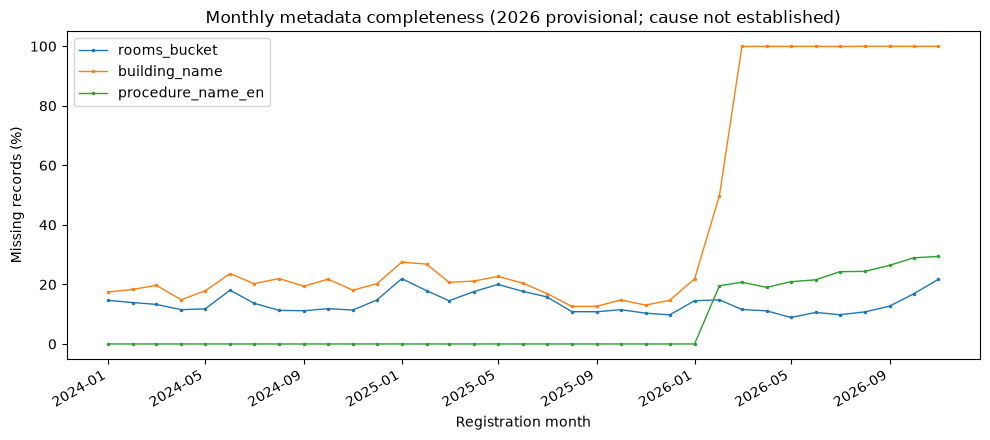

In [48]:
def temporal_completeness():
    dates=source_dates
    ym=pd.DataFrame({'year':dates.dt.year,'month':dates.dt.month},index=audit_df.index)
    rows=[]
    for (year,month),ix in ym.dropna().groupby(['year','month']).groups.items():
        g=audit_df.loc[ix]
        for field in ['has_parking','rooms_bucket','building_name','project_name','procedure_name_en','area_id']:
            rows.append(dict(year=int(year),month=int(month),field=field,n=len(g),
                missing_n=int(g[field].isna().sum()),missing_pct=100*float(g[field].isna().mean()),
                provisional=int(year)==2026))
    return pd.DataFrame(rows)
temporal_completeness=raw_result('06_temporal_quality_sensitivity',temporal_completeness,claims='RQ15')
if not temporal_completeness.empty:
    fig,ax=plt.subplots(figsize=(10,4.5))
    chosen=temporal_completeness.loc[temporal_completeness.year.ge(2024)].copy()
    chosen['period']=pd.to_datetime(dict(year=chosen.year,month=chosen.month,day=1))
    for field in ['rooms_bucket','building_name','procedure_name_en']:
        z=chosen.loc[chosen.field.eq(field)].sort_values('period')
        ax.plot(z.period,z.missing_pct,label=field,marker='.',markersize=3,lw=1)
    ax.set(xlabel='Registration month',ylabel='Missing records (%)',
       title='Monthly metadata completeness (2026 provisional; cause not established)')
    ax.legend();fig.autofmt_xdate();fig.tight_layout()
    FIGURES.append(('06_quality_timeline.png',fig,'06_temporal_quality_sensitivity',
       'Monthly observed source missingness; not evidence of a publisher policy change'))
    plt.show()


In [49]:
matching_weight_sensitivity=expose('06_matching_weighting_sensitivity',pd.concat([
    price_specification_sensitivity.assign(research='RQ01') if not price_specification_sensitivity.empty else pd.DataFrame(),
    pd.DataFrame([dict(research='RQ11',design='R4_area_year_type_rooms_size',threshold=30,
      weight_mode='pooled',change_pct=float(registration_gap_summary.gap_pct.iloc[0]),
      coverage_2025_pct=np.nan)]) if not registration_gap_summary.empty else pd.DataFrame()
],ignore_index=True,sort=False))
if not matching_weight_sensitivity.empty:
    check('RQ15','Matching robustness has explicit method and weights',
          {'research','design','threshold','weight_mode'}.issubset(matching_weight_sensitivity.columns),
          claims='RQ15',independence='A')

06_matching_weighting_sensitivity: 46 rows, 14 columns


,design,threshold,weight_mode,matched_cells,n_2021,n_2025,parent_2021,parent_2025,coverage_2021_pct,coverage_2025_pct,log_change,change_pct,effective_segments,research
0,A_broad,20,base,108.0,45257.0,128660.0,46302.0,178962.0,97.743078,71.892357,0.498489,64.623247,39.304114,RQ01
1,A_broad,20,end,108.0,45257.0,128660.0,46302.0,178962.0,97.743078,71.892357,0.496504,64.296664,32.416303,RQ01
2,A_broad,20,equal,108.0,45257.0,128660.0,46302.0,178962.0,97.743078,71.892357,0.489202,63.101352,108.000000,RQ01
3,A_broad,30,base,102.0,45119.0,123661.0,46302.0,178962.0,97.445035,69.099027,0.499604,64.806811,39.067201,RQ01
4,A_broad,30,end,102.0,45119.0,123661.0,46302.0,178962.0,97.445035,69.099027,0.513528,67.117649,31.108108,RQ01
5,A_broad,30,equal,102.0,45119.0,123661.0,46302.0,178962.0,97.445035,69.099027,0.511571,66.790938,102.000000,RQ01
6,A_broad,50,base,87.0,43569.0,120651.0,46302.0,178962.0,94.097447,67.417105,0.498936,64.696800,36.660650,RQ01
7,A_broad,50,end,87.0,43569.0,120651.0,46302.0,178962.0,94.097447,67.417105,0.512745,66.986826,29.751773,RQ01


In [50]:
def measurement():
    h=frame_for('eligible_residential_strict')
    valid=h.price_psf.notna()&np.isfinite(pd.to_numeric(h.price_psf,errors='coerce'))
    expected=h.audit_psm/10.76391041671
    d=(pd.to_numeric(h.loc[valid,'price_psf'],errors='coerce')-expected.loc[valid]).abs()
    return pd.DataFrame([dict(n=len(h),with_reported_psf=int(valid.sum()),
        reported_vs_computed_psf_median_abs_diff=float(d.median()) if len(d) else np.nan,
        reported_vs_computed_psf_p99_abs_diff=float(d.quantile(.99)) if len(d) else np.nan,
        log_price_identity_max_abs=float((h.audit_log_price-h.audit_log_area-h.audit_log_psm).abs().max()),
        note='Reported PSF is QA reference, not independent price information')])
measurement_sensitivity=raw_result('06_measurement_sensitivity',measurement,claims='RQ10,RQ14')
if not measurement_sensitivity.empty:
    check('MEASUREMENT','Price/area log identity',measurement_sensitivity.log_price_identity_max_abs.iloc[0]<1e-9,
          claims='RQ10',independence='C',critical=True)

06_measurement_sensitivity: 1 rows, 6 columns


,n,with_reported_psf,reported_vs_computed_psf_median_abs_diff,reported_vs_computed_psf_p99_abs_diff,log_price_identity_max_abs,note
0,901642,901642,0.002502,0.007033,3.552714e-15,"Reported PSF is QA reference, not independent ..."


In [51]:
# Each scenario reports *which* estimand changes. Do not compare different target populations as if identical.
def additional_flagship_sensitivities():
    if not DATA_OK:return pd.DataFrame(),pd.DataFrame()
    rows=[]
    for year in (2021,2025):
        for cohort in ['eligible_market_activity','eligible_residential_core','eligible_residential_strict']:
            h=frame_for(cohort,year,year)
            known=h.loc[h.area_id.notna()]
            counts=known.groupby('area_id',observed=True).size().to_numpy(float)
            total=counts.sum()
            hhi=float(np.sum((counts/total)**2)) if total else np.nan
            reg=h.reg_type_label.value_counts()
            ready=int(reg.get('Ready',0));off=int(reg.get('Off-Plan',0))
            rows.extend([
              dict(rq='RQ04',scenario='Geographic concentration by cohort',year=year,cohort=cohort,
                   metric='known_geography_count_hhi',estimate=hhi,n=len(known),parent_n=len(h),
                   coverage_pct=_ratio(len(known),len(h)),method='independent grouped counts'),
              dict(rq='RQ05',scenario='Registration share by cohort',year=year,cohort=cohort,
                   metric='offplan_transaction_share_pct',estimate=_ratio(off,ready+off),
                   n=ready+off,parent_n=len(h),coverage_pct=_ratio(ready+off,len(h)),
                   method='Ready/Off-Plan counts; unknown excluded only from share denominator')])
    if not community_eligibility.empty:
        one=community_eligibility.loc[community_eligibility.design.eq('A_broad')]
        for threshold in (40,50,60,70):
            eligible=one.p1_2021_n.ge(100)&one.p1_2025_n.ge(100)&one.matched_groups.ge(2)&one.effective_groups.ge(1.5)&one.coverage_2021_pct.ge(threshold)&one.coverage_2025_pct.ge(threshold)
            rows.append(dict(rq='RQ07',scenario='Community coverage gate sensitivity',year=2025,
                 cohort='P2 selected A_broad',metric='eligible_communities',estimate=int(eligible.sum()),
                 n=int(len(one)),parent_n=int(len(one)),coverage_pct=_ratio(int(eligible.sum()),len(one)),
                 method=f'At least {threshold}% supported coverage both endpoints'))
    # Recalculate RQ11 with independently defined support thresholds, retaining the original estimand.
    for threshold in (20,30,50):
        summary,matched=registration_gap_independent(threshold)
        if not summary.empty:
            q=summary.iloc[0]
            rows.append(dict(rq='RQ11',scenario='Common-support threshold',year=2025,
              cohort='P2 2020–2025 R4',metric='matched_gap_pct',estimate=float(q.gap_pct),
              n=int(q.ready_n+q.offplan_n),parent_n=int(q.ready_parent+q.offplan_parent),
              coverage_pct=_ratio(int(q.ready_n+q.offplan_n),int(q.ready_parent+q.offplan_parent)),
              method=f'R4 >= {threshold} observations per registration side'))
    # Analytic community leave-one-out is exact for a pooled-weight log gap with fixed supported strata.
    if not REG_MATCHED.empty:
        b=REG_MATCHED.assign(weighted_log=lambda x:x.mass*x.log_gap).groupby('area_id',observed=True).agg(mass=('mass','sum'),weighted_log=('weighted_log','sum'))
        mass_total=float(b.mass.sum());sum_total=float(b.weighted_log.sum())
        for a,z in b.iterrows():
            other=mass_total-float(z.mass)
            if other>0:
                rows.append(dict(rq='RQ11',scenario='Leave-one-community-out matched gap',year=2025,
                    cohort='P2 2020–2025 R4',metric='matched_gap_pct',estimate=100*np.expm1((sum_total-float(z.weighted_log))/other),
                    n=int(other),parent_n=int(mass_total),coverage_pct=_ratio(other,mass_total),method=f'Exclude observed community {a}'))
    data=pd.DataFrame(rows)
    if not data.empty:
        assert data.loc[data.rq.eq('RQ04'),'estimate'].between(0,1).all()
        assert data.loc[data.rq.eq('RQ05'),'estimate'].between(0,100).all()
    summary=[]
    for (rq,scenario,metric),g in data.groupby(['rq','scenario','metric'],dropna=False):
        summary.append(dict(rq=rq,scenario=scenario,metric=metric,available=True,
              n_scenarios=len(g),range_min=float(g.estimate.min()),range_max=float(g.estimate.max()),
              scenario_population='See 06_flagship_sensitivity_details for each cohort, threshold and denominator',
              restriction='Robustness is conditional on each recorded cohort, not population-wide or causal'))
    return data,pd.DataFrame(summary)

flagship_sensitivity_details,flagship_sensitivity_summary=(additional_flagship_sensitivities()
    if DATA_OK else (pd.DataFrame(),pd.DataFrame()))
flagship_sensitivity_details=expose('06_flagship_sensitivity_details',flagship_sensitivity_details)
scenario_rows=[]
for name,frame,rq,metric in [
    ('Matching designs',price_specification_sensitivity,'RQ01','change_pct'),
    ('Price year window',price_time_sensitivity,'RQ01','change_pct'),
    ('Core/Strict residential price',quality_policy_sensitivity,'RQ01','median_psm'),
    ('Unit/Villa tail sensitivity',size_robustness,'RQ10','delta_beta'),
    ('Missing metadata',missingness_sensitivity,'RQ12','known_pct')]:
    numeric=pd.to_numeric(frame[metric],errors='coerce') if not frame.empty and metric in frame else pd.Series(dtype=float)
    scenario_rows.append(dict(rq=rq,scenario=name,available=bool(len(numeric) and numeric.notna().any()),
        n_scenarios=len(frame),metric=metric,range_min=float(numeric.min()) if numeric.notna().any() else np.nan,
        range_max=float(numeric.max()) if numeric.notna().any() else np.nan,
        restriction='Different samples/estimands may underlie comparison; noncausal'))
research_sensitivity=expose('06_research_sensitivity',pd.concat([pd.DataFrame(scenario_rows),flagship_sensitivity_summary],ignore_index=True,sort=False))
flagships={'RQ01','RQ04','RQ05','RQ07','RQ11'}
covered=set(research_sensitivity.loc[research_sensitivity.available,'rq'])
rq15_status='QUALIFIED' if DATA_OK and flagships.issubset(covered) else 'BLOCKED'
rq15_decision=expose('06_rq15_decision',pd.DataFrame([dict(rq='RQ15',decision=rq15_status,
    required_flagships=','.join(sorted(flagships)),covered_flagships=','.join(sorted(covered&flagships)),
    reason='Flagship sensitivity computed; claim-specific lineage, scientific restrictions and release remain separate')]))
check('RQ15','Sensitivity coverage of all five required flagship RQs',flagships.issubset(covered),
    f'Missing: {sorted(flagships-covered)}',independence='A',claims='RQ15',critical=True)


06_flagship_sensitivity_details: 62 rows, 10 columns


,rq,scenario,year,cohort,metric,estimate,n,parent_n,coverage_pct,method
0,RQ04,Geographic concentration by cohort,2021,eligible_market_activity,known_geography_count_hhi,0.042678,59424,59424,100.0,independent grouped counts
1,RQ05,Registration share by cohort,2021,eligible_market_activity,offplan_transaction_share_pct,39.335959,59424,59424,100.0,Ready/Off-Plan counts; unknown excluded only f...
2,RQ04,Geographic concentration by cohort,2021,eligible_residential_core,known_geography_count_hhi,0.047358,46941,46941,100.0,independent grouped counts
3,RQ05,Registration share by cohort,2021,eligible_residential_core,offplan_transaction_share_pct,46.920602,46941,46941,100.0,Ready/Off-Plan counts; unknown excluded only f...
4,RQ04,Geographic concentration by cohort,2021,eligible_residential_strict,known_geography_count_hhi,0.047551,46302,46302,100.0,independent grouped counts
5,RQ05,Registration share by cohort,2021,eligible_residential_strict,offplan_transaction_share_pct,46.766878,46302,46302,100.0,Ready/Off-Plan counts; unknown excluded only f...
6,RQ04,Geographic concentration by cohort,2025,eligible_market_activity,known_geography_count_hhi,0.031983,214803,214803,100.0,independent grouped counts
7,RQ05,Registration share by cohort,2025,eligible_market_activity,offplan_transaction_share_pct,62.561510,214803,214803,100.0,Ready/Off-Plan counts; unknown excluded only f...


06_research_sensitivity: 10 rows, 9 columns


,rq,scenario,available,n_scenarios,metric,range_min,range_max,restriction,scenario_population
0,RQ01,Matching designs,True,45,change_pct,59.167023,67.704335,Different samples/estimands may underlie compa...,NaN
1,RQ01,Price year window,True,4,change_pct,42.064376,80.761746,Different samples/estimands may underlie compa...,NaN
2,RQ01,Core/Strict residential price,True,22,median_psm,9888.791209,18149.523543,Different samples/estimands may underlie compa...,NaN
3,RQ10,Unit/Villa tail sensitivity,True,2,delta_beta,-0.087700,-0.030392,Different samples/estimands may underlie compa...,NaN
4,RQ12,Missing metadata,True,32,known_pct,0.000000,100.000000,Different samples/estimands may underlie compa...,NaN
5,RQ04,Geographic concentration by cohort,True,6,known_geography_count_hhi,0.031983,0.047551,Robustness is conditional on each recorded coh...,See 06_flagship_sensitivity_details for each c...
6,RQ05,Registration share by cohort,True,6,offplan_transaction_share_pct,39.335959,71.878067,Robustness is conditional on each recorded coh...,See 06_flagship_sensitivity_details for each c...
7,RQ07,Community coverage gate sensitivity,True,4,eligible_communities,24.000000,27.000000,Robustness is conditional on each recorded coh...,See 06_flagship_sensitivity_details for each c...


06_rq15_decision: 1 rows, 5 columns


,rq,decision,required_flagships,covered_flagships,reason
0,RQ15,QUALIFIED,"RQ01,RQ04,RQ05,RQ07,RQ11","RQ01,RQ04,RQ05,RQ07,RQ11",Flagship sensitivity computed; claim-specific ...


True

## 09 — Statistical inference, independence and adversarial tests
**Distinguish:** transaction bootstrap (fixed groups/weights) from whole-community resampling; clustered standard errors from unobserved selection bias; fitted coefficient precision from causal identification. Multiplicity in exploratory community/interaction grids cannot be ignored.

In [52]:
def uncertainty_oracles():
    rng=np.random.default_rng(15);u=rng.normal(size=10)
    known=np.repeat(.3,10)
    simple=float(np.average(known,weights=np.arange(1,11)))
    ratio=float(100*np.expm1(simple))
    return pd.DataFrame([dict(oracle='Fixed positive weighted log gap',expected_log=.3,actual_log=simple,
       expected_pct=100*np.expm1(.3),actual_pct=ratio,passed=_close(simple,.3))])
uncertainty_oracles_df=expose('06_uncertainty_method_validation',uncertainty_oracles())
check('INFERENCE','Synthetic known-effect log gap',uncertainty_oracles_df.passed.all(),independence='C',critical=True,claims='RQ11')

06_uncertainty_method_validation: 1 rows, 6 columns


,oracle,expected_log,actual_log,expected_pct,actual_pct,passed
0,Fixed positive weighted log gap,0.3,0.3,34.985881,34.985881,True


True

In [53]:
def identification_review():
    rows=[]
    for question,table,stat in [('RQ10',size_identity,'groups'),('RQ11',registration_gap_summary,'communities'),
                                 ('RQ12',parking_support,'communities')]:
        rows.append(dict(rq=question,available=not table.empty,independent_groups=int(table[stat].min()) if not table.empty and stat in table else None,
            inference='Observed independent groups; rank/covariance/counterfactual restrictions still apply'))
    return pd.DataFrame(rows)
model_identification=expose('06_model_identification_validation',identification_review())

06_model_identification_validation: 3 rows, 4 columns


,rq,available,independent_groups,inference
0,RQ10,True,983,Observed independent groups; rank/covariance/c...
1,RQ11,True,43,Observed independent groups; rank/covariance/c...
2,RQ12,True,9,Observed independent groups; rank/covariance/c...


In [54]:
def multiplicity():
    n_groups=int(community_eligibility.drop_duplicates('area_id').matched_price_eligible.sum()) if not community_eligibility.empty and {'area_id','matched_price_eligible'}.issubset(community_eligibility.columns) else 0
    return pd.DataFrame([dict(domain='Community/subgroup exploratory comparisons',
        candidate_tests=n_groups,significance_claim_allowed=False,
        rule='No selected significant coefficient without declared test family; no automatic ranking'),
        dict(domain='RQ11 R4 primary descriptive contrast',candidate_tests=1,significance_claim_allowed=False,
        rule='Point estimate and cluster sensitivity only; causal inference prohibited')])
multiple_comparison_audit=expose('06_multiple_comparison_audit',multiplicity())

06_multiple_comparison_audit: 2 rows, 4 columns


,domain,candidate_tests,significance_claim_allowed,rule
0,Community/subgroup exploratory comparisons,34,False,No selected significant coefficient without de...
1,RQ11 R4 primary descriptive contrast,1,False,Point estimate and cluster sensitivity only; c...


In [55]:
def adversarial_cases():
    samples=[]
    def add(name,p,reason):samples.append(dict(case=name,passed=bool(p),reason=reason))
    # Test reference encoding (1, 1.0 must represent the same bedroom reference).
    categories=pd.Series([0.,1.,2.,3.,4.,5.]).astype('int64').astype(str)
    dummies=pd.get_dummies(categories,prefix='BR');dummies=dummies.drop(columns=['BR_1'])
    add('Canonical 1BR dummy removed',dummies.shape[1]==5 and 'BR_1' not in dummies,'Do not mix string 1 with 1.0')
    # Known two-cell weighted geometric difference.
    w=np.array([.25,.75]);changes=np.log(np.array([2.,4.])/np.array([1.,2.]))
    add('Known weighted log change',_close(float(w@changes),np.log(2)),'Weights normalized')
    # No common support means NO estimate, not a zero effect.
    n0=np.array([20,40]);n1=np.array([0,5]);add('No overlap withheld',not np.any((n0>=30)&(n1>=30)),'No accidental zeros')
    # Log(price/area)=log(price)-log(area), exact independent identity.
    p=np.array([500000.,1200000.,2300000.]);a=np.array([50.,80.,115.]);
    add('Price-area log identity',np.allclose(np.log(p/a),np.log(p)-np.log(a),atol=1e-12),'Denominator coupling')
    # Key perturbation: changing a reference price must alter verified metric.
    x=np.array([10.,20.,30.]);add('Corrupted price detected',not _close(float(x.mean()),float(np.array([10.,20.,35.]).mean())),'Corruption not silently accepted')
    return pd.DataFrame(samples)
adversarial_results=expose('06_adversarial_test_results',adversarial_cases())
check('ADVERSARIAL','Independent synthetic oracles',adversarial_results.passed.all(),independence='C',claims='ALL',critical=True)

06_adversarial_test_results: 5 rows, 3 columns


,case,passed,reason
0,Canonical 1BR dummy removed,True,Do not mix string 1 with 1.0
1,Known weighted log change,True,Weights normalized
2,No overlap withheld,True,No accidental zeros
3,Price-area log identity,True,Denominator coupling
4,Corrupted price detected,True,Corruption not silently accepted


True

In [56]:
stat_reliability=expose('06_statistical_reliability',pd.DataFrame([
 dict(rq='RQ01',status='QUALIFIED' if DATA_OK and not price_index_independent.empty else 'BLOCKED',reason='Matched group medians; no constant-quality stock-wide identification'),
 dict(rq='RQ06',status='INCONCLUSIVE' if '03' in UPSTREAM_NBS else 'BLOCKED',reason='Chronological increment not independently established'),
 dict(rq='RQ07',status='QUALIFIED' if DATA_OK and not community_growth_checks.empty else 'BLOCKED',reason='Selected areas; not an all-community index'),
 dict(rq='RQ10',status='QUALIFIED' if DATA_OK and not size_identity.empty else 'BLOCKED',reason='Size-price algebra verified but confounding and tails remain'),
 dict(rq='RQ11',status='QUALIFIED' if DATA_OK and not registration_uncertainty.empty else 'BLOCKED',reason='Community resampling conditional on observed support; no causal premium'),
 dict(rq='RQ12',status='QUALIFIED' if DATA_OK and not bedroom_contrasts.empty else 'BLOCKED',reason='Only supported bedroom contrasts; parking withheld or inconclusive')
]))

06_statistical_reliability: 6 rows, 3 columns


,rq,status,reason
0,RQ01,QUALIFIED,Matched group medians; no constant-quality sto...
1,RQ06,INCONCLUSIVE,Chronological increment not independently esta...
2,RQ07,QUALIFIED,Selected areas; not an all-community index
3,RQ10,QUALIFIED,Size-price algebra verified but confounding an...
4,RQ11,QUALIFIED,Community resampling conditional on observed s...
5,RQ12,QUALIFIED,Only supported bedroom contrasts; parking with...


## 10 — Final research decisions and dashboard release policy
**Fail closed:** A claim cannot pass if its independent prerequisites or mandatory exported evidence fail. A verified exact count may be SUPPORTED while model-derived prices remain QUALIFIED. Unverified does not mean zero, false or NOT ESTIMABLE.

In [57]:
def extracted_table(prefix, variable):
    """Read the displayed pandas table from the *specified* executed notebook cell.
    This is Level D notebook evidence, not a claim that an unavailable CSV exists.
    """
    nb=UPSTREAM_NBS.get(prefix)
    if not nb:return pd.DataFrame()
    for cell in reversed(nb.get('cells', [])):
        code=''.join(cell.get('source', []))
        if not re.search(r'display\(\s*'+re.escape(variable)+r'\b',code):
            continue
        for output in cell.get('outputs', []):
            html=''.join(output.get('data', {}).get('text/html', []))
            if '<table' not in html:continue
            try:
                for found in pd.read_html(StringIO(html), keep_default_na=False):
                    found.columns=[str(x) for x in found.columns]
                    found=found.loc[:,~pd.Index(found.columns).str.match(r'^Unnamed:')]
                    if len(found) and len(found.columns):return found.reset_index(drop=True)
            except (ValueError,ImportError):continue
    return pd.DataFrame()

def retrieve_source_decisions(prefix):
    """Use actual upstream output variable names, verified in the uploaded .ipynb files."""
    names={
       '01':['01_research_findings','01_market_research_decisions'],
       '02':['02_price_research_decisions'],
       '03':['03_research_findings'],
       '04':['04_research_findings'],
       '05':['05_research_findings'],
    }
    variables={
       '01':['research_findings','market_research_decisions'],
       '02':['price_research_decisions'],
       '03':['activity_research_findings'],
       '04':['community_research_findings'],
       '05':['research_findings'],
    }
    for stem in names.get(prefix,[]):
        path=TABLE_DIR/f'{stem}.csv'
        if path.is_file():
            try:
                table=pd.read_csv(path,low_memory=False)
                if len(table)>0 and ('research_question' in table or 'rq' in table or 'rq_id' in table):
                    return table,'VERIFIED_CSV',path
            except Exception as exc:
                issue('ARTIFACTS','UPSTREAM_FINDINGS_UNREADABLE','BLOCKED',f'{path}: {exc}', 'RELEASE')
    for var in variables.get(prefix,[]):
        table=extracted_table(prefix,var)
        if len(table)>0 and {'research_question','rq','rq_id'}.intersection(table.columns):
            return table,'SAVED_NOTEBOOK_OUTPUT_LEVEL_D',None
    return pd.DataFrame(),'MISSING_VERIFIABLE_FINDINGS',None

upstream_claims=[];evidence_provenance=[]
for prefix in EXPECTED_NOTEBOOKS:
    if prefix=='00':
        evidence_provenance.append(dict(notebook=prefix,source='FEASIBILITY_NOT_FINDINGS',rows=0,
            csv_exists=False,notebook_sha256=next((x.get('sha256') for x in notebook_rows if x['notebook']==prefix),None)))
        continue
    findings,level,path=retrieve_source_decisions(prefix)
    evidence_provenance.append(dict(notebook=prefix,source=level,rows=len(findings),
        csv_exists=path is not None,csv_sha256=digest(path) if path else None,
        notebook_sha256=next((x.get('sha256') for x in notebook_rows if x['notebook']==prefix),None)))
    if level=='SAVED_NOTEBOOK_OUTPUT_LEVEL_D':
        issue('ARTIFACTS','UPSTREAM_CSV_NOT_SUPPLIED','QUALIFIED',
              f'Notebook {prefix} has actual saved findings, but its research-decisions CSV was not supplied', 'RELEASE')
    if findings.empty:
        issue('CLAIMS','UPSTREAM_FINDINGS_NOT_IDENTIFIABLE','BLOCKED',
              f'Notebook {prefix} has no readable findings CSV or individually identifiable executed findings table',
              'RELEASE')
    else:
        findings=findings.copy()
        findings['source_notebook']=prefix
        findings['source_evidence_level']=level
        upstream_claims.append(findings)
upstream_findings=expose('06_upstream_finding_registry',
    pd.concat(upstream_claims,ignore_index=True,sort=False) if upstream_claims else pd.DataFrame())
findings_provenance=expose('06_upstream_findings_provenance',pd.DataFrame(evidence_provenance))
print('Upstream claim evidence:',len(upstream_findings),'rows; source provenance:',
      findings_provenance[['notebook','source','rows']].to_dict('records'))


06_upstream_finding_registry: 36 rows, 26 columns


,claim_id,research_question,population,start_year,end_year,metric,start_value,end_value,delta,relative_change_pct,...,restriction,source_notebook,source_evidence_level,estimand,design,estimate_pct,matched_coverage_min_pct,uncertainty_interval,rq,source_sha256
0,MKT01,RQ04,P0_ALL_SALES,2021.0,2025.0,Registered transaction count,5.942400e+04,2.148030e+05,1.553790e+05,261.475162,...,"Recorded sales, not unique properties, complet...",01,VERIFIED_CSV,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,MKT02,RQ04,P0_ALL_SALES,2021.0,2025.0,Recorded gross sale consideration,1.483502e+11,6.823304e+11,5.339802e+11,359.945797,...,Registered consideration is NOT developer rece...,01,VERIFIED_CSV,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,MKT03,RQ14,P0_ALL_SALES,2021.0,2025.0,Mean transaction consideration,2.496469e+06,3.176540e+06,6.800713e+05,27.241328,...,Mean is sensitive to high-value transactions a...,01,VERIFIED_CSV,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,MKT04,RQ14,P0_ALL_SALES,2021.0,2025.0,Median transaction consideration,1.448431e+06,1.550000e+06,1.015690e+05,7.012346,...,Median is not comparable-home appreciation.,01,VERIFIED_CSV,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,MKT05,RQ14,P0_ALL_SALES,2021.0,2025.0,Mean/median consideration ratio,1.723568e+00,2.049381e+00,3.258131e-01,18.903409,...,"A distribution diagnostic, not a residential p...",01,VERIFIED_CSV,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,PROP01,RQ04,P0_ALL_SALES,2021.0,2025.0,Count of Unit / Residential registered sales,3.598400e+04,1.664950e+05,1.305110e+05,362.691752,...,Largest signed category contribution is accoun...,01,VERIFIED_CSV,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,REG01,RQ05,P0_ALL_SALES,2021.0,2025.0,Off-Plan registered transaction count share,3.933596e+01,6.256151e+01,2.322555e+01,59.044071,...,"Registration classification, not developer cas...",01,VERIFIED_CSV,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,GEO01,RQ04,P0_KNOWN_GEOGRAPHY,2021.0,2025.0,Known-community transaction-count HHI,4.267759e-02,3.198318e-02,-1.069441e-02,-25.058614,...,"HHI uses observed community IDs, not housing-s...",01,VERIFIED_CSV,NaN,NaN,NaN,NaN,NaN,NaN,NaN


06_upstream_findings_provenance: 6 rows, 6 columns


,notebook,source,rows,csv_exists,notebook_sha256,csv_sha256
0,00,FEASIBILITY_NOT_FINDINGS,0,False,594e1cde21bf0f85020f0018a36249e9d758bf43f8f9bf...,NaN
1,01,VERIFIED_CSV,12,True,7042e226ff3a44e5d924440e1227137c41b0831756bfe3...,0423374c2742c4a8cc05048fb8330d783bf7c954b1d6f2...
2,02,VERIFIED_CSV,7,True,a1919fd4591050bba60a21a95daf4eac54890ddd07cd10...,fff4823b86c16c25ef23117d03cb54750ee4b3ba86c264...
3,03,VERIFIED_CSV,7,True,4b07708aae5d1253736ba49c211a136d580b3984a75436...,acaab953942014292f20cacfef1dcc5679f83ead8d516f...
4,04,VERIFIED_CSV,6,True,3a93f64e50ce66758bbcb408eb3be6b66fb2db8f799ac1...,c1c39eeb95038035d439a624c21b457471b0bf7ae2bcea...
5,05,VERIFIED_CSV,4,True,8530a3077a49093f003d437d1c50ff7253c96222e250e7...,329d1003a2a70fcd4ae3e8287e610fbda08d6268ff1954...


Upstream claim evidence: 36 rows; source provenance: [{'notebook': '00', 'source': 'FEASIBILITY_NOT_FINDINGS', 'rows': 0}, {'notebook': '01', 'source': 'VERIFIED_CSV', 'rows': 12}, {'notebook': '02', 'source': 'VERIFIED_CSV', 'rows': 7}, {'notebook': '03', 'source': 'VERIFIED_CSV', 'rows': 7}, {'notebook': '04', 'source': 'VERIFIED_CSV', 'rows': 6}, {'notebook': '05', 'source': 'VERIFIED_CSV', 'rows': 4}]


In [58]:
def contradiction_report():
    issues=pd.DataFrame(ISSUES)
    cols=['section','code','severity','detail','affected_rqs','source']
    return issues[cols].copy() if not issues.empty else pd.DataFrame(columns=cols)
contradictions=expose('06_unresolved_research_issues',contradiction_report())
compare_registry=expose('06_contradiction_register',pd.DataFrame(COMPARES) if COMPARES else pd.DataFrame(columns=['rq','metric','abs_diff','units','result']))
print('Unresolved blocking evidence issues:',int(contradictions.severity.eq('BLOCKED').sum()) if not contradictions.empty else 0)

06_unresolved_research_issues: 2 rows, 6 columns


,section,code,severity,detail,affected_rqs,source
0,COHORTS,COHORT_EXPORT_GAPS,QUALIFIED,One or more upstream cohort CSVs unavailable; ...,ALL,06 independent audit
1,RQ06,POINT_IN_TIME_SOURCE_LIMITATION,QUALIFIED,Publisher flags and whole-snapshot derived var...,RQ06,06 independent audit


06_contradiction_register: 6 rows, 5 columns


,rq,metric,abs_diff,units,result
0,RQ01,A_broad,0.000000e+00,percentage points,PASS
1,RQ01,B_bedrooms,0.000000e+00,percentage points,PASS
2,RQ01,C_size_only,0.000000e+00,percentage points,PASS
3,RQ01,D_size_bedrooms,0.000000e+00,percentage points,PASS
4,RQ01,E_fine_bedrooms,7.105427e-15,percentage points,PASS
5,RQ11,matched_gap_pct,0.000000e+00,percentage points,PASS


Unresolved blocking evidence issues: 0


In [59]:
BASELINE={
 'RQ01':('02','QUALIFIED'),'RQ02':('02','QUALIFIED'),'RQ03':('01,04','QUALIFIED'),
 'RQ04':('01,03','SUPPORTED'),'RQ05':('01,03','SUPPORTED'),'RQ06':('03','INCONCLUSIVE'),
 'RQ07':('04','QUALIFIED'),'RQ08':('04','QUALIFIED'),'RQ09':('04','QUALIFIED'),
 'RQ10':('05','QUALIFIED'),'RQ11':('05','QUALIFIED'),'RQ12':('05','QUALIFIED'),
 'RQ13':('04','QUALIFIED'),'RQ14':('01','QUALIFIED'),'RQ15':('06','QUALIFIED')}
# Exact filenames are checked against the uploaded source of each notebook, not guessed from the original plan.
REQUIRED_ARTIFACTS={
 'RQ01':[('02','price_index_endpoint'),('02','price_research_decisions')],
 'RQ02':[('02','area_mix_decomposition'),('02','price_research_decisions')],
 'RQ03':[('01','budget_summary')],
 'RQ04':[('01','market_summary'),('03','community_concentration_yearly')],
 'RQ05':[('01','registration_contributions')],
 'RQ06':[('03','activity_lead_lag_validation')],
 'RQ07':[('04','matching_decisions')],
 'RQ08':[('04','dispersion_yearly')],
 'RQ09':[('04','activity_price_regimes')],
 'RQ10':[('05','size_price_linear_models')],
 'RQ11':[('05','offplan_ready_matched_gap')],
 'RQ12':[('05','bedroom_contrast_support'),('05','parking_overlap_feasibility')],
 'RQ13':[('04','price_stability')],
 'RQ14':[('01','price_tail_summary')],
 'RQ15':[]}
CALC_AVAILABLE={
 'RQ01':not price_index_independent.empty,'RQ02':not area_decomposition.empty,
 'RQ03':not budget_tail_totals.empty,
 'RQ04':not activity_growth.empty and not concentration_totals.empty,
 'RQ05':not registration_growth_bridge.empty,
 'RQ06':False,
 'RQ07':not community_growth_checks.empty,
 'RQ08':not community_dispersion.empty,
 'RQ09':not community_regimes.empty and community_regimes.status.iloc[0]=='CLASSIFICATION_VERIFIED',
 'RQ10':not size_identity.empty,'RQ11':not registration_gap_summary.empty,
 'RQ12':not bedroom_contrasts.empty and not parking_support.empty,
 'RQ13':not community_stability.empty and community_stability.status.iloc[0]!='BLOCKED',
 'RQ14':not budget_tail_totals.empty,
 'RQ15':DATA_OK and rq15_status=='QUALIFIED'}

def evidence_for_artifact(prefix,stem):
    path=TABLE_DIR/f'{prefix}_{stem}.csv'
    if path.is_file():
        try:
            f=pd.read_csv(path,low_memory=False)
            if len(f)>0 and len(f.columns)>0:return 'ACTUAL_CSV',str(path)
        except Exception as exc:return 'UNREADABLE_CSV',f'{path}: {exc}'
    candidate_variables={
      '02_price_index_endpoint':'price_index_endpoint',
      '02_area_mix_decomposition':'area_mix_decomposition',
      '02_price_research_decisions':'price_research_decisions',
    }
    var=candidate_variables.get(f'{prefix}_{stem}')
    if var and len(extracted_table(prefix,var))>0:
        return 'SAVED_NOTEBOOK_TABLE_ONLY',f'{prefix}:{var}'
    return 'MISSING_EVIDENCE',str(path)

rows=[]
for rq,(origins,initial) in BASELINE.items():
    required=REQUIRED_ARTIFACTS.get(rq,[])
    availability=[(p,stem,*evidence_for_artifact(p,stem)) for p,stem in required]
    absent=[f'{p}_{stem} ({level})' for p,stem,level,loc in availability if level!='ACTUAL_CSV']
    unsourced=[f'{p}_{stem}' for p,stem,level,loc in availability if level in ('MISSING_EVIDENCE','UNREADABLE_CSV')]
    scientific_failures=relevant_blockers(rq,ISSUES)
    computed=bool(DATA_OK and CALC_AVAILABLE.get(rq,False))
    if rq=='RQ06':
        final='INCONCLUSIVE' if '03' in UPSTREAM_NBS and DATA_OK else 'BLOCKED'
        reason='Incremental out-of-time predictive evidence not independently established'
    elif scientific_failures or not computed:
        final='BLOCKED';reason='Independent verification failed or mandatory scientific evidence is not evaluable'
    else:
        final=initial
        reason='Core numerical verification completed; original observational and population restrictions retained'
    # A missing file affects publication readiness; it does not change a reproduced coefficient.
    evidence_complete=(len(absent)==0 and len(unsourced)==0)
    rows.append(dict(rq_id=rq,upstream_notebook=origins,upstream_status=initial,
      final_status=final,independent_source_recomputed=computed,
      missing_required_artifacts='; '.join(absent),missing_essential_evidence='; '.join(unsourced),
      evidence_artifacts_verified=evidence_complete,unresolved_scientific_dependencies=len(scientific_failures),
      claim_specific_replication_complete=False,
      reason=reason,restriction='Descriptive/observational only; preserve all per-claim restrictions and denominator definitions'))
claim_evidence=expose('06_claim_evidence_register',pd.DataFrame(rows))
final_research_decisions=expose('06_final_research_decisions',
  claim_evidence[['rq_id','final_status','reason','restriction','evidence_artifacts_verified']].copy())
subclaims=[]
for j,claim in upstream_findings.reset_index(drop=True).iterrows():
    record=claim.to_dict()
    rq,mapping_issue=map_claim_rq(record)
    upstream_status=str(record.get('decision',record.get('status','UNSPECIFIED')))
    if upstream_status=='nan':upstream_status='UNSPECIFIED'
    parent=claim_evidence.set_index('rq_id').loc[rq] if rq in set(claim_evidence.rq_id) else None
    known=(parent is not None and parent.final_status in ('SUPPORTED','QUALIFIED') and
           upstream_status in ('SUPPORTED','QUALIFIED') and not mapping_issue)
    subclaims.append(dict(upstream_claim_id=(str(record['claim_id']) if pd.notna(record.get('claim_id')) and str(record.get('claim_id')).strip() else f'{record.get("source_notebook","??")}-row-{j}'),
       rq_id=rq if rq else ('CROSS_CUTTING' if mapping_issue=='CROSS_CUTTING_SOURCE_FINDING' else 'UNMAPPED'),source_notebook=str(record.get('source_notebook','')),
       upstream_decision=upstream_status,
       final_publication_status=('QUALIFIED_NOT_RELEASED' if known else 'WITHHELD'),
       evidence_level=str(record.get('source_evidence_level','UNVERIFIED')),
       published=False, # claim-level independent reconstruction and release must both pass
       interpretation=str(record.get('interpretation',record.get('estimand',record.get('description','')))),
       restriction=str(record.get('restriction','')),
       issue_if_withheld=mapping_issue or 'Claim-level independent acceptance and project release not completed'))
subclaim_evidence=expose('06_subclaim_evidence_register',pd.DataFrame(subclaims) if subclaims else
    pd.DataFrame(columns=['upstream_claim_id','rq_id','source_notebook','upstream_decision',
     'final_publication_status','evidence_level','published','interpretation','restriction','issue_if_withheld']))
if not subclaim_evidence.empty and subclaim_evidence.rq_id.eq('UNMAPPED').any():
    issue('CLAIMS','CLAIM_MAPPING_INCOMPLETE','BLOCKED',
      'Unmapped claim identifiers: '+str(subclaim_evidence.loc[subclaim_evidence.rq_id.eq('UNMAPPED'),'upstream_claim_id'].tolist()),'RELEASE')
check('CLAIMS','All RQ01–RQ15 present exactly once',set(claim_evidence.rq_id)==set(RQ_IDS) and claim_evidence.rq_id.is_unique,
    independence='C',claims='ALL',critical=True)
check('CLAIMS','No scientific decision upgraded from upstream status',all(z.final_status==z.upstream_status or
   z.final_status in ('BLOCKED','INCONCLUSIVE') for z in claim_evidence.itertuples()),independence='C',claims='ALL',critical=True)
check('CLAIMS','Every identifiable upstream claim mapped to a single RQ',not subclaim_evidence.empty and
   not subclaim_evidence.rq_id.eq('UNMAPPED').any(),
   details=f'{int(subclaim_evidence.rq_id.eq("UNMAPPED").sum()) if not subclaim_evidence.empty else "none"} unmapped',
   independence='D',claims='RELEASE',critical=False)
check('CLAIMS','No subclaim auto-published without claim-specific evidence',not subclaim_evidence.published.any(),
    independence='C',claims='RELEASE',critical=True)


06_claim_evidence_register: 15 rows, 12 columns


,rq_id,upstream_notebook,upstream_status,final_status,independent_source_recomputed,missing_required_artifacts,missing_essential_evidence,evidence_artifacts_verified,unresolved_scientific_dependencies,claim_specific_replication_complete,reason,restriction
0,RQ01,02,QUALIFIED,QUALIFIED,True,,,True,0,False,Core numerical verification completed; origina...,Descriptive/observational only; preserve all p...
1,RQ02,02,QUALIFIED,QUALIFIED,True,,,True,0,False,Core numerical verification completed; origina...,Descriptive/observational only; preserve all p...
2,RQ03,"01,04",QUALIFIED,QUALIFIED,True,,,True,0,False,Core numerical verification completed; origina...,Descriptive/observational only; preserve all p...
3,RQ04,"01,03",SUPPORTED,SUPPORTED,True,,,True,0,False,Core numerical verification completed; origina...,Descriptive/observational only; preserve all p...
4,RQ05,"01,03",SUPPORTED,SUPPORTED,True,,,True,0,False,Core numerical verification completed; origina...,Descriptive/observational only; preserve all p...
5,RQ06,03,INCONCLUSIVE,INCONCLUSIVE,False,,,True,0,False,Incremental out-of-time predictive evidence no...,Descriptive/observational only; preserve all p...
6,RQ07,04,QUALIFIED,QUALIFIED,True,,,True,0,False,Core numerical verification completed; origina...,Descriptive/observational only; preserve all p...
7,RQ08,04,QUALIFIED,QUALIFIED,True,,,True,0,False,Core numerical verification completed; origina...,Descriptive/observational only; preserve all p...


06_final_research_decisions: 15 rows, 5 columns


,rq_id,final_status,reason,restriction,evidence_artifacts_verified
0,RQ01,QUALIFIED,Core numerical verification completed; origina...,Descriptive/observational only; preserve all p...,True
1,RQ02,QUALIFIED,Core numerical verification completed; origina...,Descriptive/observational only; preserve all p...,True
2,RQ03,QUALIFIED,Core numerical verification completed; origina...,Descriptive/observational only; preserve all p...,True
3,RQ04,SUPPORTED,Core numerical verification completed; origina...,Descriptive/observational only; preserve all p...,True
4,RQ05,SUPPORTED,Core numerical verification completed; origina...,Descriptive/observational only; preserve all p...,True
5,RQ06,INCONCLUSIVE,Incremental out-of-time predictive evidence no...,Descriptive/observational only; preserve all p...,True
6,RQ07,QUALIFIED,Core numerical verification completed; origina...,Descriptive/observational only; preserve all p...,True
7,RQ08,QUALIFIED,Core numerical verification completed; origina...,Descriptive/observational only; preserve all p...,True


06_subclaim_evidence_register: 36 rows, 10 columns


,upstream_claim_id,rq_id,source_notebook,upstream_decision,final_publication_status,evidence_level,published,interpretation,restriction,issue_if_withheld
0,MKT01,RQ04,01,SUPPORTED,QUALIFIED_NOT_RELEASED,VERIFIED_CSV,False,"Registered transaction count increased by 155,...","Recorded sales, not unique properties, complet...",Claim-level independent acceptance and project...
1,MKT02,RQ04,01,SUPPORTED,QUALIFIED_NOT_RELEASED,VERIFIED_CSV,False,Recorded gross sale consideration increased by...,Registered consideration is NOT developer rece...,Claim-level independent acceptance and project...
2,MKT03,RQ14,01,SUPPORTED,QUALIFIED_NOT_RELEASED,VERIFIED_CSV,False,Mean transaction consideration increased by 68...,Mean is sensitive to high-value transactions a...,Claim-level independent acceptance and project...
3,MKT04,RQ14,01,SUPPORTED,QUALIFIED_NOT_RELEASED,VERIFIED_CSV,False,Median transaction consideration increased by ...,Median is not comparable-home appreciation.,Claim-level independent acceptance and project...
4,MKT05,RQ14,01,QUALIFIED,QUALIFIED_NOT_RELEASED,VERIFIED_CSV,False,Mean/median consideration ratio increased by 0...,"A distribution diagnostic, not a residential p...",Claim-level independent acceptance and project...
5,PROP01,RQ04,01,SUPPORTED,QUALIFIED_NOT_RELEASED,VERIFIED_CSV,False,Count of Unit / Residential registered sales i...,Largest signed category contribution is accoun...,Claim-level independent acceptance and project...
6,REG01,RQ05,01,SUPPORTED,QUALIFIED_NOT_RELEASED,VERIFIED_CSV,False,Off-Plan registered transaction count share in...,"Registration classification, not developer cas...",Claim-level independent acceptance and project...
7,GEO01,RQ04,01,SUPPORTED,QUALIFIED_NOT_RELEASED,VERIFIED_CSV,False,Known-community transaction-count HHI decrease...,"HHI uses observed community IDs, not housing-s...",Claim-level independent acceptance and project...


True

In [60]:
DASHBOARD_PAGES={
 'Market Overview':['RQ04','RQ05'],
 'Price Reality':['RQ01','RQ02','RQ03','RQ14'],
 'Community Intelligence':['RQ07','RQ08','RQ09','RQ13'],
 'Market Structure':['RQ10','RQ11','RQ12'],
 'Data Reliability':['RQ15']}
agg_rules={'registered_count':'sum across disjoint cohorts only',
 'registered_value_aed':'sum across disjoint cohorts only',
 'median_price':'never average medians; recompute from transactions or precomputed matching grain',
 'matched_gap':'never aggregate coefficients without supported strata and weights',
 'price_index':'never recompute under arbitrary dashboard filters'}
rows=[]
for page,rqs in DASHBOARD_PAGES.items():
    for rq in rqs:
        record=claim_evidence.set_index('rq_id').loc[rq]
        rows.append(dict(page=page,rq=rq,final_status=record.final_status,
           publishable=record.final_status in ('SUPPORTED','QUALIFIED'),
           dashboard_rule='Use precomputed permitted grain; display population & caveat; no causal/investment language',
           filter_policy='No arbitrary regrouping of medians, weighted indices, FE coefficients or selected contrasts'))
dashboard_readiness=expose('06_dashboard_readiness',pd.DataFrame(rows))
check('DASHBOARD','No blocked claim released',not dashboard_readiness.loc[dashboard_readiness.final_status.eq('BLOCKED'),'publishable'].any(),
      claims='ALL',independence='C',critical=True)

06_dashboard_readiness: 14 rows, 6 columns


,page,rq,final_status,publishable,dashboard_rule,filter_policy
0,Market Overview,RQ04,SUPPORTED,True,Use precomputed permitted grain; display popul...,"No arbitrary regrouping of medians, weighted i..."
1,Market Overview,RQ05,SUPPORTED,True,Use precomputed permitted grain; display popul...,"No arbitrary regrouping of medians, weighted i..."
2,Price Reality,RQ01,QUALIFIED,True,Use precomputed permitted grain; display popul...,"No arbitrary regrouping of medians, weighted i..."
3,Price Reality,RQ02,QUALIFIED,True,Use precomputed permitted grain; display popul...,"No arbitrary regrouping of medians, weighted i..."
4,Price Reality,RQ03,QUALIFIED,True,Use precomputed permitted grain; display popul...,"No arbitrary regrouping of medians, weighted i..."
5,Price Reality,RQ14,QUALIFIED,True,Use precomputed permitted grain; display popul...,"No arbitrary regrouping of medians, weighted i..."
6,Community Intelligence,RQ07,QUALIFIED,True,Use precomputed permitted grain; display popul...,"No arbitrary regrouping of medians, weighted i..."
7,Community Intelligence,RQ08,QUALIFIED,True,Use precomputed permitted grain; display popul...,"No arbitrary regrouping of medians, weighted i..."


True

## 11 — Audit outputs, reproducibility and final publication decision
Exports in this notebook are new **06_*** artifacts. Earlier notebooks and source modules are read-only. Missing evidence is exported in issue/decision registries, never replaced with zero. The audit may finish with BLOCKED claims: this is an intended scientific outcome.

In [61]:
# Re-check selected invariants before final export. Failures propagate through the issue register.
summary_checks=pd.DataFrame(CHECKS)
if not summary_checks.empty:
    summary_checks=expose('06_research_validation',summary_checks)
    print('Checks passed:',int(summary_checks.passed.sum()),'/',len(summary_checks))
else:summary_checks=expose('06_research_validation',pd.DataFrame(columns=['section','check','passed','details']))
# Ensure final issue registry includes all diagnostic failures.
final_issues=expose('06_final_issue_register',pd.DataFrame(ISSUES) if ISSUES else pd.DataFrame(columns=['section','code','severity','detail','affected_rqs','source']))
if DATA_OK and any(not bool(z) for z in summary_checks.loc[summary_checks.critical,'passed']):
    print('Critical validation check failed: affected claims must be BLOCKED')

06_research_validation: 39 rows, 7 columns


,section,check,passed,details,independence_level,affected_rqs,critical
0,SOURCE,Frozen snapshot SHA-256,True,,A,ALL,True
1,SOURCE,20 raw fields,True,,A,ALL,True
2,SOURCE,Unique nonnull transaction IDs,True,,A,ALL,True
3,POPULATIONS,Independent cohort membership exact,True,"{'eligible_market_activity': 0, 'eligible_resi...",A,ALL,True
4,POPULATIONS,2026 excluded from 2010–2025,True,,A,ALL,False
5,QUALITY,Bit counts are not assumed exclusive,True,,A,RQ15,False
6,NULLS,Source fields preserved,True,,A,ALL,False
7,COHORTS,P2 subset P1 strict,True,,A,ALL,True


Checks passed: 39 / 39
06_final_issue_register: 2 rows, 7 columns


,section,code,severity,detail,affected_rqs,source,detected_at
0,COHORTS,COHORT_EXPORT_GAPS,QUALIFIED,One or more upstream cohort CSVs unavailable; ...,ALL,06 independent audit,06-20261124T040907Z
1,RQ06,POINT_IN_TIME_SOURCE_LIMITATION,QUALIFIED,Publisher flags and whole-snapshot derived var...,RQ06,06 independent audit,06-20261124T040907Z


In [62]:
# Phase 1: export scientific tables. Final mutable reports are exported in phase 2.
for folder in (TABLE_DIR,AGG_DIR,FIG_DIR):folder.mkdir(parents=True,exist_ok=True)
export_records=[]
MANDATORY_NONEMPTY={'06_source_provenance','06_independent_cohort_membership',
 '06_price_index_independent','06_registration_gap_independent',
 '06_research_sensitivity','06_research_validation'}
FINAL_REPORT_NAMES={'06_claim_evidence_register','06_final_research_decisions','06_dashboard_readiness',
    '06_subclaim_evidence_register','06_export_manifest','06_figure_validation',
    '06_reproducibility_acceptance','06_research_findings','06_final_issue_register'}

def write_verified_table(name,table):
    """Type-aware full-cell verification of CSV and Parquet, including nullable booleans.

    CSV is intrinsically untyped. A reserved null marker, string-safe serialization,
    and the ORIGINAL column dtype govern readback; never infer numeric from 'True'.
    """
    if not isinstance(table,pd.DataFrame):
        return dict(name=name,status='BLOCKED',rows=0,error='NOT_DATAFRAME')
    # An empty terminal issue ledger is a legitimate PASS artifact: export and
    # verify its schema, rather than treating zero unresolved issues as missing.
    if table.empty and name!='06_final_issue_register':
        required=name in MANDATORY_NONEMPTY
        return dict(name=name,status='BLOCKED' if required else 'WITHHELD_EMPTY',rows=0,
                    error='Required evidence unavailable' if required else 'No supported data')
    dest_csv=TABLE_DIR/f'{name}.csv';dest_pq=AGG_DIR/f'{name}.parquet'
    v=table.copy().reset_index(drop=True);v.columns=v.columns.astype(str)
    missing_token='__V2_MISSING_'+RUN_ID.replace('-','_')+'__'
    try:
        if v.columns.duplicated().any():raise ValueError('Duplicate column labels')
        # Reserve the marker across all textual representations, including literal categories.
        for col in v.columns:
            values=v[col]
            if values.notna().any() and values[values.notna()].astype(str).eq(missing_token).any():
                raise ValueError(f'{col}: Reserved missing marker collides with data')
        # Serialize each scalar explicitly so dtype-specific to_csv null formatting
        # cannot conflate 0, False, empty string, NA, None and pandas missing values.
        encoded=pd.DataFrame(index=v.index)
        for col in v.columns:
            original=v[col]
            encoded[col]=pd.Series([missing_token if pd.isna(x) else str(x)
                                    for x in original.tolist()],index=v.index,dtype='string')
        encoded.to_csv(dest_csv,index=False)
        v.to_parquet(dest_pq,index=False,engine='pyarrow')
        reread=pd.read_parquet(dest_pq,engine='pyarrow').reset_index(drop=True)
        ok,reason=verify_frame_values(v,reread)
        if not ok:raise AssertionError('Parquet readback: '+reason)
        csv=pd.read_csv(dest_csv,low_memory=False,dtype=str,keep_default_na=False,na_filter=False)
        if list(csv.columns)!=list(v.columns) or len(csv)!=len(v):
            raise AssertionError('CSV schema or row count')
        for col in v.columns:
            a=v[col].reset_index(drop=True);b=csv[col].reset_index(drop=True)
            missing=a.isna()
            if not missing.equals(b.eq(missing_token)):
                raise AssertionError(f'{col}: CSV missing-value mask')
            if bool(missing.all()):continue
            aa=a.loc[~missing].reset_index(drop=True)
            bb=b.loc[~missing].reset_index(drop=True)
            if pd.api.types.is_bool_dtype(a.dtype):
                # Numeric dtypes include bool in some pandas versions; test this FIRST.
                if not bb.isin(['True','False']).all():
                    raise AssertionError(f'{col}: CSV invalid boolean token')
                if not aa.astype(bool).reset_index(drop=True).equals(bb.eq('True')):
                    raise AssertionError(f'{col}: CSV boolean values')
            elif pd.api.types.is_integer_dtype(a.dtype):
                if not all(int(x)==int(y) for x,y in zip(aa,bb)):
                    raise AssertionError(f'{col}: CSV integer values')
            elif pd.api.types.is_numeric_dtype(a.dtype):
                av=pd.to_numeric(aa,errors='raise').to_numpy(dtype=float)
                bv=pd.to_numeric(bb,errors='raise').to_numpy(dtype=float)
                if not np.allclose(av,bv,rtol=1e-12,atol=1e-14,equal_nan=False):
                    raise AssertionError(f'{col}: CSV numeric values')
            elif not aa.astype(str).equals(bb.astype(str)):
                raise AssertionError(f'{col}: CSV categorical values')
        return dict(name=name,status='VERIFIED',rows=len(v),csv_sha256=digest(dest_csv),
                    parquet_sha256=digest(dest_pq),error='',csv_bytes=dest_csv.stat().st_size,
                    parquet_bytes=dest_pq.stat().st_size)
    except Exception as exc:
        return dict(name=name,status='BLOCKED',rows=len(v),error=f'{type(exc).__name__}: {exc}',
                    csv_sha256=digest(dest_csv) if dest_csv.is_file() else None,
                    parquet_sha256=digest(dest_pq) if dest_pq.is_file() else None)

for name,table in sorted(TABLES.items()):
    if name in FINAL_REPORT_NAMES:continue
    record=write_verified_table(name,table)
    export_records.append(record)
    if record['status']=='BLOCKED':
        issue('EXPORT','EXPORT_OR_READBACK_FAILED','BLOCKED',f'{name}: {record["error"]}','RELEASE')
export_manifest=expose('06_export_manifest',pd.DataFrame(export_records))


06_export_manifest: 63 rows, 8 columns


,name,status,rows,csv_sha256,parquet_sha256,error,csv_bytes,parquet_bytes
0,06_activity_growth_reconciliation,VERIFIED,1,eb2ef227e681394561e8f92da9e6a57d80b6ab075d3c79...,c9ad176e137ac20f135d9ae5cf4590f431efa1be6bc399...,,167,5322
1,06_adversarial_test_results,VERIFIED,5,12726145181b3ab84cfc53e82943cb7cc1e71ea23bfb49...,d47edaaca78301d9da63215035375c64c6076de991704a...,,295,2509
2,06_area_decomposition_reconciliation,VERIFIED,1,b46a4d986b464b90f988f575486f77d4d049cc12bc0546...,616cf7fe1fbbf225eddc8b66c6cbc3d2a1b570cf88d15b...,,282,6134
3,06_bedroom_contrast_validation,VERIFIED,5,cbe3cf7af9f35dd516a7f319aa7196f85f9f27894ef8bd...,f9743ef422f1034365c036e6127243ea911968934550ad...,,646,5043
4,06_budget_tail_reconciliation,VERIFIED,64,7d6c0d5834acc523f089f1f4ae572154786564a9e79e70...,b68715156f938901ea94d31e666915483fce12443edc46...,,6930,6492
5,06_community_dispersion_validation,VERIFIED,2,b7e8226841cac84fe22da08e97cc08e378add415b7a37f...,61150c31e0778307f2e65ab698e0b906756df4c8c6e4bd...,,201,4172
6,06_community_eligibility_reconciliation,VERIFIED,406,5fc8081a6f5c73c2999fae067832efd74f584717c2ede5...,9dd829a0c0cf80bbd929b089a8903ad6f8172bcc31296c...,,39378,15022
7,06_community_growth_independent_checks,VERIFIED,6,973e4cc5d39218aae4249eab843aeaf4c668e525c42eb4...,3e407f7d3d28cfdb60b20011e11596d721c4feae330928...,,908,4756


In [63]:
fig_records=[]
for filename,fig,table,restriction in FIGURES:
    dest=FIG_DIR/filename
    try:
        fig.savefig(dest,dpi=160,bbox_inches='tight')
        fig_records.append(dict(figure=filename,source_table=table,exists=dest.is_file(),
                                bytes=dest.stat().st_size,sha256=digest(dest),restriction=restriction))
    except Exception as exc:
        issue('FIGURES','FIGURE_EXPORT_FAILED','BLOCKED',f'{filename}: {exc}','ALL')
        fig_records.append(dict(figure=filename,source_table=table,exists=False,bytes=0,sha256=None,restriction=str(exc)))
figure_validation=expose('06_figure_validation',pd.DataFrame(fig_records))
for x in FIGURES:plt.close(x[1])

06_figure_validation: 2 rows, 6 columns


,figure,source_table,exists,bytes,sha256,restriction
0,06_cohort_selection.png,06_integrated_population_selection,True,45776,c6f2fd3d3079fd7b244945d5b4213085e21675a07e5658...,Historical source; parent denominators in table
1,06_quality_timeline.png,06_temporal_quality_sensitivity,True,89763,2d487648f07f124a4e20701c0db7baa0058ca94b3b15ec...,Monthly observed source missingness; not evide...


In [64]:
# Finalization is fail-closed and release-wide failures never erase correctly
# reproduced scientific estimates. Files are verified by actual readback.
pytest_report=dict(executed=False,return_code=None,summary='NOT RUN',command='python -m pytest -q -W error')
try:
    result=subprocess.run([sys.executable,'-m','pytest','-q','-W','error'],cwd=ROOT,
                           capture_output=True,text=True,timeout=240)
    pytest_report.update(executed=True,return_code=result.returncode,
        summary=' '.join(re.sub(r'\x1b\[[0-9;]*m','',(result.stdout+' '+result.stderr)).split())[-700:])
except Exception as exc:
    pytest_report['summary']=f'{type(exc).__name__}: {exc}'
pytest_ok=bool(pytest_report['executed'] and pytest_report['return_code']==0)
if not pytest_ok:
    issue('TESTS','AUTOMATED_SUITE_NOT_PASSED','BLOCKED',pytest_report['summary'],'RELEASE')
if ' skipped' in pytest_report['summary']:
    issue('TESTS','TESTS_SKIPPED','QUALIFIED',pytest_report['summary'],'RELEASE')

# Apply only genuine scientific failures to the research-question statuses.
for rq in claim_evidence.rq_id:
    blockers=relevant_blockers(rq,ISSUES)
    if blockers:
        selector=claim_evidence.rq_id.eq(rq)
        claim_evidence.loc[selector,'final_status']='BLOCKED'
        claim_evidence.loc[selector,'reason']='Independent scientific dependency unresolved: '+', '.join(
           sorted(set(str(b['code']) for b in blockers)))
        claim_evidence.loc[selector,'unresolved_scientific_dependencies']=len(blockers)

# Missing upstream files are release/evidence-lineage failures, not falsification
# of independently reproduced values.
for record in claim_evidence.itertuples():
    if not record.evidence_artifacts_verified:
        issue('ARTIFACTS','UPSTREAM_LINEAGE_UNVERIFIED','BLOCKED',
              f'{record.rq_id}: {record.missing_required_artifacts}', 'RELEASE')

final_research_decisions=claim_evidence[['rq_id','final_status','reason','restriction',
                                         'evidence_artifacts_verified']].copy()
dashboard_readiness['final_status']=dashboard_readiness.rq.map(
    claim_evidence.set_index('rq_id').final_status)
dashboard_readiness['scientifically_eligible']=dashboard_readiness.final_status.isin(['SUPPORTED','QUALIFIED'])
dashboard_readiness['evidence_artifacts_verified']=dashboard_readiness.rq.map(
    claim_evidence.set_index('rq_id').evidence_artifacts_verified)
# No claim is published solely because its parent RQ achieved a coherent arithmetic result.
subclaim_evidence['published']=False
subclaim_evidence['release_approved']=False
dashboard_readiness['publishable']=False

final_export_rows=[]
def export_final(name,table):
    verdict=write_verified_table(name,table)
    final_export_rows.append(verdict)
    if verdict['status']=='BLOCKED':
        issue('FINAL_EXPORT','READBACK_OR_WRITE_FAILED','BLOCKED',
              f'{name}: {verdict.get("error","")}', 'RELEASE')
    return verdict

for name,frame in [
 ('06_claim_evidence_register',claim_evidence),
 ('06_final_research_decisions',final_research_decisions),
 ('06_subclaim_evidence_register',subclaim_evidence),
 ('06_figure_validation',figure_validation),
]:export_final(name,frame)

all_sources_ok=bool(DATA_OK and source_verified)
notebooks_complete=bool(len(execution_inventory)==6 and execution_inventory.status.eq('COMPLETE').all())
check_registry_ok=bool(not summary_checks.empty and summary_checks.passed.all())
primary_files_ok=bool(export_records and all(t['status'] in ('VERIFIED','WITHHELD_EMPTY') for t in export_records))
nonempty_required_ok=all(any(r['name']==name and r['status']=='VERIFIED' and r['rows']>0 for r in export_records)
                         for name in MANDATORY_NONEMPTY)
figure_ok=bool(figure_validation.empty or figure_validation.exists.fillna(False).all())
claim_map_ok=bool(not subclaim_evidence.empty and not subclaim_evidence.rq_id.eq('UNMAPPED').any())
evidence_chain_ok=bool(claim_evidence.evidence_artifacts_verified.all())
scientific_export_ok=bool(all(x['status'] in ('VERIFIED','WITHHELD_EMPTY') for x in final_export_rows))
blocking_issues=any(x['severity']=='BLOCKED' for x in ISSUES)

publication_ready=bool(all_sources_ok and notebooks_complete and check_registry_ok and primary_files_ok
    and nonempty_required_ok and figure_ok and claim_map_ok and evidence_chain_ok
    and scientific_export_ok and pytest_ok and not blocking_issues)
release_status='APPROVED_WITH_QUALIFICATIONS' if publication_ready else 'RELEASE_BLOCKED'
# Publication is an explicit conjunction of scientific eligibility, verified
# upstream evidence and final release readiness.
dashboard_readiness['publishable']=(dashboard_readiness.scientifically_eligible &
    dashboard_readiness.evidence_artifacts_verified & publication_ready)

final_findings=claim_evidence[['rq_id','final_status','reason','restriction',
   'independent_source_recomputed','missing_required_artifacts','evidence_artifacts_verified']].copy()
final_findings['source_sha256']=SOURCE_SHA
final_findings['run_id']=RUN_ID

def reproduction_frame():
    return pd.DataFrame([dict(run_id=RUN_ID,source_sha256=SOURCE_SHA,
       real_source_read=DATA_OK,notebooks_complete=notebooks_complete,
       internal_checks_pass=check_registry_ok,
       primary_exports_verified=primary_files_ok and nonempty_required_ok,
       actual_upstream_lineage_verified=evidence_chain_ok,
       pytest_executed=pytest_report['executed'],pytest_returncode=pytest_report['return_code'],
       pytest_summary=pytest_report['summary'],
       scientific_status_counts=str(claim_evidence.final_status.value_counts().to_dict()),
       release_status=release_status,ready_for_qualified_publication=publication_ready,
       ready_for_unrestricted_publication=False)])

reproducibility=reproduction_frame()
for name,frame in [('06_dashboard_readiness',dashboard_readiness),
                   ('06_reproducibility_acceptance',reproducibility),
                   ('06_research_findings',final_findings)]:export_final(name,frame)

# If a late report export failed, revoke release and persist a consistent status.
if any(x['status']=='BLOCKED' for x in final_export_rows) and publication_ready:
    publication_ready=False;release_status='RELEASE_BLOCKED'
    dashboard_readiness['publishable']=False
    reproducibility=reproduction_frame()
    for name,frame in [('06_dashboard_readiness',dashboard_readiness),
                       ('06_reproducibility_acceptance',reproducibility)]:
        export_final(name,frame)

# Scientific and release checks refer to explicit, testable obligations.
final_gate_checks=pd.DataFrame([
 dict(check='15 unique final RQ decisions',passed=len(final_research_decisions)==15 and final_research_decisions.rq_id.is_unique and set(final_research_decisions.rq_id)==set(RQ_IDS)),
 dict(check='Every upstream specific claim is mapped or explicitly cross-cutting',passed=claim_map_ok),
 dict(check='No subclaim published from parent-level-only checks',passed=not subclaim_evidence.published.any()),
 dict(check='Dashboard release status equals final gate',passed=bool(dashboard_readiness.publishable.any())==bool(publication_ready and dashboard_readiness.scientifically_eligible.any())),
 dict(check='Every required upstream CSV actually available',passed=evidence_chain_ok),
 dict(check='All mandatory audited tables verified and nonempty',passed=nonempty_required_ok),
 dict(check='Scientific tables passed CSV and Parquet readback',passed=primary_files_ok and scientific_export_ok),
 dict(check='Source and six upstream notebooks verified',passed=all_sources_ok and notebooks_complete),
 dict(check='106+ project tests collected with no failures',passed=pytest_ok),
 dict(check='No unresolved critical issue in release',passed=not any(x['severity']=='BLOCKED' for x in ISSUES)),
])
if not final_gate_checks.passed.all():
    publication_ready=False;release_status='RELEASE_BLOCKED'
    dashboard_readiness['publishable']=False
    reproducibility=reproduction_frame()
    # These amendments occur before writing the final manifest / final issue ledger.
    export_final('06_dashboard_readiness',dashboard_readiness)
    export_final('06_reproducibility_acceptance',reproducibility)
    for row in final_gate_checks.loc[~final_gate_checks.passed].itertuples():
        if not any(x['section']=='FINALIZATION' and x['detail']==row.check for x in ISSUES):
            issue('FINALIZATION','RELEASE_REQUIREMENT_NOT_MET','BLOCKED',row.check,'RELEASE')
export_final('06_finalization_checks',final_gate_checks)

# The terminal issue register is immutable within a successful finalization.
# An export manifest cannot hash itself. It enumerates all other exported tables,
# including terminal issues; its own readback is checked separately.
final_issues=(pd.DataFrame(ISSUES) if ISSUES else
              pd.DataFrame(columns=['section','code','severity','detail','affected_rqs','source','detected_at']))
issues_result=write_verified_table('06_final_issue_register',final_issues)
if issues_result['status']!='VERIFIED':
    publication_ready=False;release_status='RELEASE_BLOCKED'
    print('CRITICAL: terminal issue registry export not verified:',issues_result.get('error'))
all_export_records=export_records+final_export_rows+[issues_result]
# Deduplicate only when a final report was deliberately rewritten; retain the
# most recent successful/failed record for its actual canonical path.
record_by_name={r['name']:r for r in all_export_records}
export_manifest=pd.DataFrame([record_by_name[k] for k in sorted(record_by_name)])
manifest_result=write_verified_table('06_export_manifest',export_manifest)
if manifest_result['status']!='VERIFIED':
    publication_ready=False;release_status='RELEASE_BLOCKED'
    issue('FINAL_EXPORT','MANIFEST_FAILED','BLOCKED',manifest_result.get('error'),'RELEASE')
    # A late failure is never omitted from the terminal issue ledger.
    final_issues=pd.DataFrame(ISSUES)
    issues_result=write_verified_table('06_final_issue_register',final_issues)
    record_by_name['06_final_issue_register']=issues_result
    export_manifest=pd.DataFrame([record_by_name[k] for k in sorted(record_by_name)])
    manifest_result=write_verified_table('06_export_manifest',export_manifest)

# Verify that the terminal export manifest points to actual unchanged artifacts.
# This does not claim to verify its own hash (self-reference is impossible).
manifest_integrity=[]
for rec in export_manifest.to_dict('records'):
    if rec.get('status')!='VERIFIED':
        continue
    name=rec['name']
    csv_path=TABLE_DIR/f'{name}.csv';pq_path=AGG_DIR/f'{name}.parquet'
    ok=(csv_path.is_file() and pq_path.is_file() and
        digest(csv_path)==rec.get('csv_sha256') and
        digest(pq_path)==rec.get('parquet_sha256'))
    manifest_integrity.append(bool(ok))
if not all(manifest_integrity):
    publication_ready=False;release_status='RELEASE_BLOCKED'
    issue('FINAL_EXPORT','MANIFEST_HASH_INTEGRITY_FAILED','BLOCKED',
          'A terminal manifest entry does not match the actual exported file', 'RELEASE')
    final_issues=pd.DataFrame(ISSUES)
    issues_result=write_verified_table('06_final_issue_register',final_issues)
    record_by_name['06_final_issue_register']=issues_result
    export_manifest=pd.DataFrame([record_by_name[k] for k in sorted(record_by_name)])
    manifest_result=write_verified_table('06_export_manifest',export_manifest)

# If an end-stage infrastructure failure arose, the release must remain blocked
# even if earlier scientific estimates were independently reproducible.
if not publication_ready:
    release_status='RELEASE_BLOCKED'
    dashboard_readiness['publishable']=False
    reproducibility=reproduction_frame()
    dashboard_status=write_verified_table('06_dashboard_readiness',dashboard_readiness)
    reproducibility_status=write_verified_table('06_reproducibility_acceptance',reproducibility)
    record_by_name['06_dashboard_readiness']=dashboard_status
    record_by_name['06_reproducibility_acceptance']=reproducibility_status
    record_by_name['06_final_issue_register']=issues_result
    export_manifest=pd.DataFrame([record_by_name[k] for k in sorted(record_by_name)])
    manifest_result=write_verified_table('06_export_manifest',export_manifest)

for name,frame in [('06_claim_evidence_register',claim_evidence),
 ('06_final_research_decisions',final_research_decisions),
 ('06_subclaim_evidence_register',subclaim_evidence),
 ('06_dashboard_readiness',dashboard_readiness),
 ('06_figure_validation',figure_validation),
 ('06_export_manifest',export_manifest),
 ('06_finalization_checks',final_gate_checks),
 ('06_final_issue_register',final_issues),
 ('06_reproducibility_acceptance',reproducibility),
 ('06_research_findings',final_findings)]:TABLES[name]=frame.copy()
print('FINAL CHECKS:',int(final_gate_checks.passed.sum()),'/',len(final_gate_checks))
print('MANIFEST:',manifest_result.get('status'),
      '| ISSUE REGISTER:',issues_result.get('status'))
print('PYTEST:',pytest_report['summary'])
print('SCIENTIFIC RQ DECISIONS:',claim_evidence.final_status.value_counts().to_dict())
print('PROJECT RELEASE:',release_status,'| publishable dashboard claims:',int(dashboard_readiness.publishable.sum()))
display(reproducibility)
display(final_research_decisions)
display(final_issues)


FINAL CHECKS: 10 / 10
MANIFEST: VERIFIED | ISSUE REGISTER: VERIFIED
PYTEST: ........................................................................ [ 54%] ............................................................ [100%] 132 passed in 36.09s
SCIENTIFIC RQ DECISIONS: {'QUALIFIED': 12, 'SUPPORTED': 2, 'INCONCLUSIVE': 1}
PROJECT RELEASE: APPROVED_WITH_QUALIFICATIONS | publishable dashboard claims: 14


,run_id,source_sha256,real_source_read,notebooks_complete,internal_checks_pass,primary_exports_verified,actual_upstream_lineage_verified,pytest_executed,pytest_returncode,pytest_summary,scientific_status_counts,release_status,ready_for_qualified_publication,ready_for_unrestricted_publication
0,06-20261124T040907Z,8294c3dd83dde2e16e64eaf1ef155a1ad14ec16b6b3938...,True,True,True,True,True,True,0,.................................................,"{'QUALIFIED': 12, 'SUPPORTED': 2, 'INCONCLUSIV...",APPROVED_WITH_QUALIFICATIONS,True,False


,rq_id,final_status,reason,restriction,evidence_artifacts_verified
0,RQ01,QUALIFIED,Core numerical verification completed; origina...,Descriptive/observational only; preserve all p...,True
1,RQ02,QUALIFIED,Core numerical verification completed; origina...,Descriptive/observational only; preserve all p...,True
2,RQ03,QUALIFIED,Core numerical verification completed; origina...,Descriptive/observational only; preserve all p...,True
3,RQ04,SUPPORTED,Core numerical verification completed; origina...,Descriptive/observational only; preserve all p...,True
4,RQ05,SUPPORTED,Core numerical verification completed; origina...,Descriptive/observational only; preserve all p...,True
5,RQ06,INCONCLUSIVE,Incremental out-of-time predictive evidence no...,Descriptive/observational only; preserve all p...,True
6,RQ07,QUALIFIED,Core numerical verification completed; origina...,Descriptive/observational only; preserve all p...,True
7,RQ08,QUALIFIED,Core numerical verification completed; origina...,Descriptive/observational only; preserve all p...,True
8,RQ09,QUALIFIED,Core numerical verification completed; origina...,Descriptive/observational only; preserve all p...,True
9,RQ10,QUALIFIED,Core numerical verification completed; origina...,Descriptive/observational only; preserve all p...,True


,section,code,severity,detail,affected_rqs,source,detected_at
0,COHORTS,COHORT_EXPORT_GAPS,QUALIFIED,One or more upstream cohort CSVs unavailable; ...,ALL,06 independent audit,06-20261124T040907Z
1,RQ06,POINT_IN_TIME_SOURCE_LIMITATION,QUALIFIED,Publisher flags and whole-snapshot derived var...,RQ06,06 independent audit,06-20261124T040907Z
